# Hábitos alimentares da população adulta de Curitiba

Este notebook analisa as mudanças nos hábitos alimentares da população adulta de Curitiba a partir dos dados do **Vigitel**, considerando tanto a evolução dos indicadores ao longo do tempo quanto as diferenças entre grupos da população.

**Pergunta de pesquisa:**  
Como os hábitos alimentares da população adulta de Curitiba mudaram ao longo do tempo e como essas mudanças variam entre diferentes grupos da população?

A análise está organizada em duas etapas. Primeiro, são investigadas as principais tendências temporais dos indicadores alimentares. Em seguida, são analisadas diferenças segundo sexo, idade e escolaridade. Os principais resultados encontrados neste notebook serão aprofundados no **Notebook 02 — Investigação sociológica**.

## 1. Dados e metodologia

Os dados utilizados são provenientes do **Vigitel**, inquérito do Ministério da Saúde que monitora fatores de risco e proteção para doenças crônicas entre adultos das capitais brasileiras.

A análise foi restrita aos participantes residentes em Curitiba. Como a disponibilidade dos indicadores varia entre as edições do Vigitel, cada série temporal utiliza os anos comparáveis disponíveis para aquele indicador.

As prevalências foram calculadas utilizando o peso amostral disponibilizado pelo Vigitel (`pesorake2025`). Além dos indicadores de consumo alimentar, foram utilizadas informações sobre **sexo, idade e escolaridade** para analisar diferenças entre grupos da população.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

arquivo_vigitel = '/content/drive/MyDrive/PUC/TCC/PORTFOLIO/PROJETO 1/vigitel-2006-2024-peso-rake_slabel.csv'

print('Arquivo encontrado:', os.path.isfile(arquivo_vigitel))

Arquivo encontrado: True


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import os

# Verificar o diretório atual de trabalho
cwd = os.getcwd()
print(f"Diretório atual de trabalho (CWD): {cwd}\n")

# Listar todos os arquivos no diretório atual
print("Arquivos encontrados no diretório atual:")
arquivos = os.listdir('.')
for arquivo in arquivos:
    print(f"- {arquivo}")

# Procurar especificamente pelos arquivos do Vigitel no sistema de arquivos para ajudar a localizá-los
print("\nBuscando arquivos específicos no ambiente:")
for root, dirs, files in os.walk('/content'):
    for file in files:
        if 'vigitel' in file.lower() or 'dicionario' in file.lower() or 'dicionário' in file.lower():
            print(f"Encontrado: {os.path.join(root, file)}")

Diretório atual de trabalho (CWD): /content

Arquivos encontrados no diretório atual:
- .config
- drive
- sample_data

Buscando arquivos específicos no ambiente:
Encontrado: /content/drive/MyDrive/Graduação/RI /TCC/2019/fichamentos /BOBBIO - DICIONARIO DE POLITICA .gdoc
Encontrado: /content/drive/MyDrive/PUC/PYTHON/Trabalho final/Listas/Lista 4 - Tuplas e Dicionarios.pdf
Encontrado: /content/drive/MyDrive/PUC/TCC/PORTFOLIO/PROJETO 1/vigitel-2006-2024-peso-rake_slabel.csv
Encontrado: /content/drive/MyDrive/PUC/TCC/PORTFOLIO/PROJETO 1/dicionario-vigitel-2006-2024.xlsx
Encontrado: /content/drive/MyDrive/PUC/TCC/PORTFOLIO/PROJETO 1/Notebook principal — 01_analise_vigitel_curitiba.ipynb


### 1.1 Carregamento e preparação dos dados

In [ ]:
arquivo_vigitel = '/content/drive/MyDrive/PUC/TCC/PORTFOLIO/PROJETO 1/vigitel-2006-2024-peso-rake_slabel.csv'

arquivo_dicionario = '/content/drive/MyDrive/PUC/TCC/PORTFOLIO/PROJETO 1/dicionario-vigitel-2006-2024.xlsx'

dicionario = pd.read_excel(
    arquivo_dicionario,
    header=2
)

### 1.2 Indicadores analisados

Foram selecionados indicadores relacionados ao consumo de **frutas, hortaliças, feijão, refrigerantes, doces, leite integral, carnes com excesso de gordura, substituição de refeições por lanches e alimentos ultraprocessados**.

A disponibilidade desses indicadores varia entre as edições do Vigitel. Por isso, as análises consideram apenas os anos em que cada variável apresenta definição comparável.

Também foram selecionadas as variáveis **sexo, idade e escolaridade** para investigar diferenças nos hábitos alimentares entre grupos da população.

In [ ]:
# Carregar a aba de indicadores do Vigitel
indicadores = pd.read_excel(
    arquivo_dicionario,
    sheet_name='Indicadores_Vigitel',
    header=2
)

In [ ]:
# Indicadores alimentares selecionados para a análise
indicadores_alimentacao = [
    'hortareg',
    'frutareg',
    'flvreg',
    'cruadia',
    'cozidadia',
    'hortadia',
    'sucodia',
    'sofrutadia',
    'frutadia',
    'flvdia',
    'flvreco',
    'flvreco_pns',
    'carneg',
    'franpl',
    'gordura',
    'leiteint',
    'doces5',
    'refritl5',
    'feijao5',
    'score_sf_2cat',
    'score_upp_2cat2024',
    'score_upp_2cat',
    'lanche_7',
    'cont_lanche_7',
    'sal'
]

In [ ]:
# Ler apenas os nomes das colunas da base Vigitel
colunas_vigitel = pd.read_csv(
    arquivo_vigitel,
    encoding='latin1',
    nrows=0
).columns.tolist()

In [ ]:
# Selecionar as variáveis necessárias
colunas_selecionadas = [
    'ano',
    'cidade',
    'pesorake2025'
] + indicadores_alimentacao

# Carregar somente as colunas selecionadas
dados = pd.read_csv(
    arquivo_vigitel,
    encoding='latin1',
    usecols=colunas_selecionadas
)

# Filtrar os participantes de Curitiba
curitiba = dados[
    dados['cidade'] == 7
].copy()

print(f'Observações de Curitiba: {len(curitiba):,}')
print(f'Período disponível: {int(curitiba["ano"].min())}–{int(curitiba["ano"].max())}')

Observações de Curitiba: 31,196
Período disponível: 2006–2024


In [ ]:
# Verificar a disponibilidade temporal de cada indicador
disponibilidade = []

for indicador in indicadores_alimentacao:
    anos = sorted(
        curitiba.loc[
            curitiba[indicador].notna(),
            'ano'
        ].unique()
    )

    disponibilidade.append({
        'Indicador': indicador,
        'Primeiro ano': min(anos) if len(anos) > 0 else None,
        'Último ano': max(anos) if len(anos) > 0 else None,
        'Nº de edições': len(anos)
    })

disponibilidade = pd.DataFrame(disponibilidade)

display(disponibilidade)

,Indicador,Primeiro ano,Último ano,Nº de edições
0,hortareg,2006,2024,18
1,frutareg,2006,2024,18
2,flvreg,2008,2024,16
3,cruadia,2006,2024,18
4,cozidadia,2009,2024,15
5,hortadia,2006,2024,18
6,sucodia,2008,2024,16
7,sofrutadia,2008,2024,16
8,frutadia,2006,2024,18
9,flvdia,2006,2024,18


In [ ]:
# Indicadores binários utilizados na análise
indicadores_binarios = [
    'hortareg',
    'frutareg',
    'flvreg',
    'flvreco',
    'flvreco_pns',
    'carneg',
    'franpl',
    'gordura',
    'leiteint',
    'doces5',
    'refritl5',
    'feijao5',
    'score_sf_2cat',
    'score_upp_2cat',
    'score_upp_2cat2024',
    'lanche_7',
    'sal'
]

## 2. Como os hábitos alimentares mudaram ao longo do tempo?

Nesta etapa, são analisadas as mudanças nos principais indicadores alimentares ao longo das edições do Vigitel disponíveis para Curitiba. As prevalências são calculadas utilizando os pesos amostrais da pesquisa.

In [ ]:
# Função para calcular a prevalência ponderada
def prevalencia_ponderada(dados, indicador, peso='pesorake2025'):

    # Manter somente registros válidos para o indicador e para o peso
    validos = dados[
        dados[indicador].notna() &
        dados[peso].notna()
    ]

    # Calcular a prevalência ponderada
    prevalencia = (
        (validos[indicador] * validos[peso]).sum()
        / validos[peso].sum()
    ) * 100

    return prevalencia

In [ ]:
# Calcular a prevalência ponderada de todos os indicadores binários por ano

resultados_binarios = []

for indicador in indicadores_binarios:

    for ano in sorted(curitiba['ano'].unique()):

        dados_ano = curitiba[curitiba['ano'] == ano]

        # Calcular apenas quando houver dados para o indicador naquele ano
        if dados_ano[indicador].notna().any():

            prevalencia = prevalencia_ponderada(
                dados_ano,
                indicador
            )

            resultados_binarios.append({
                'Indicador': indicador,
                'Ano': ano,
                'Prevalência (%)': prevalencia
            })

resultados_binarios = pd.DataFrame(resultados_binarios)

In [ ]:
# Organizar as prevalências em uma tabela: anos nas linhas e indicadores nas colunas

tabela_prevalencias = resultados_binarios.pivot(
    index='Ano',
    columns='Indicador',
    values='Prevalência (%)'
)

# Arredondar para uma casa decimal
tabela_prevalencias = tabela_prevalencias.round(1)

In [ ]:
# Criar nomes mais claros para os indicadores

nomes_indicadores = {
    'hortareg': 'Hortaliças regularmente',
    'frutareg': 'Frutas regularmente',
    'flvreg': 'Frutas e hortaliças regularmente',
    'flvreco': 'Consumo recomendado de frutas e hortaliças',
    'flvreco_pns': 'Consumo recomendado de frutas e hortaliças (PNS)',
    'carneg': 'Carne com gordura',
    'franpl': 'Frango com pele',
    'gordura': 'Carnes com excesso de gordura',
    'leiteint': 'Leite integral',
    'doces5': 'Doces regularmente',
    'refritl5': 'Refrigerantes regularmente',
    'feijao5': 'Feijão regularmente',
    'score_sf_2cat': 'Cinco ou mais grupos de alimentos protetores',
    'score_upp_2cat2024': 'Ultraprocessados — indicador 2024',
    'score_upp_2cat': 'Cinco ou mais grupos de ultraprocessados',
    'lanche_7': 'Substituição de refeições por lanches',
    'sal': 'Consumo de sal alto ou muito alto'
}

# Criar uma cópia com nomes legíveis
tabela_prevalencias_legivel = tabela_prevalencias.rename(
    columns=nomes_indicadores
)

### 2.1 Frutas e hortaliças

In [ ]:
# Definir as colunas desejadas que realmente existem no DataFrame para evitar KeyError
colunas_desejadas = ['hortareg', 'frutareg', 'flvreg', 'flvreco']
colunas_existentes = [col for col in colunas_desejadas if col in tabela_prevalencias.columns]

bloco_frutas_hortalicas = tabela_prevalencias[colunas_existentes].copy()

bloco_frutas_hortalicas = bloco_frutas_hortalicas.rename(
    columns=nomes_indicadores
)

In [ ]:
teste_anos = pd.read_csv(
    arquivo_vigitel,
    encoding="latin1",
    usecols=["ano"]
)

print(sorted(teste_anos["ano"].unique()))
print("Ano mínimo:", teste_anos["ano"].min())
print("Ano máximo:", teste_anos["ano"].max())
print("Total de linhas:", len(teste_anos))

[np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2023), np.int64(2024)]
Ano mínimo: 2006
Ano máximo: 2024
Total de linhas: 833217


In [ ]:
print(sorted(dados["ano"].unique()))

[np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2023), np.int64(2024)]


In [ ]:
# Importar a função de regressão linear
from scipy.stats import linregress

# Analisar a tendência linear dos indicadores de frutas e hortaliças
tendencias_frutas_hortalicas = []

for indicador in bloco_frutas_hortalicas.columns:

    # Remover os anos sem dados para este indicador
    serie = bloco_frutas_hortalicas[indicador].dropna()

    # Calcular a regressão linear
    resultado = linregress(
        serie.index.astype(float),
        serie.values
    )

    # Armazenar os resultados
    tendencias_frutas_hortalicas.append({
        'Indicador': indicador,
        'Nº de anos': len(serie),
        'Variação média anual (p.p.)': resultado.slope,
        'p-valor': resultado.pvalue,
        'R²': resultado.rvalue ** 2
    })

# Transformar os resultados em uma tabela
tendencias_frutas_hortalicas = pd.DataFrame(
    tendencias_frutas_hortalicas
)

# Exibir os resultados
display(tendencias_frutas_hortalicas.round(3))


,Indicador,Nº de anos,Variação média anual (p.p.),p-valor,R²
0,Hortaliças regularmente,18,-0.067,0.531,0.025
1,Frutas regularmente,18,0.416,0.023,0.285
2,Frutas e hortaliças regularmente,16,0.120,0.413,0.048
3,Consumo recomendado de frutas e hortaliças,16,0.196,0.179,0.125


Na análise exploratória, o consumo regular de frutas foi o único dos quatro indicadores a apresentar tendência linear crescente, com aumento estimado de 0,416 ponto percentual ao ano (p = 0,023).

Os demais indicadores não apresentaram evidência de tendência linear na análise realizada.

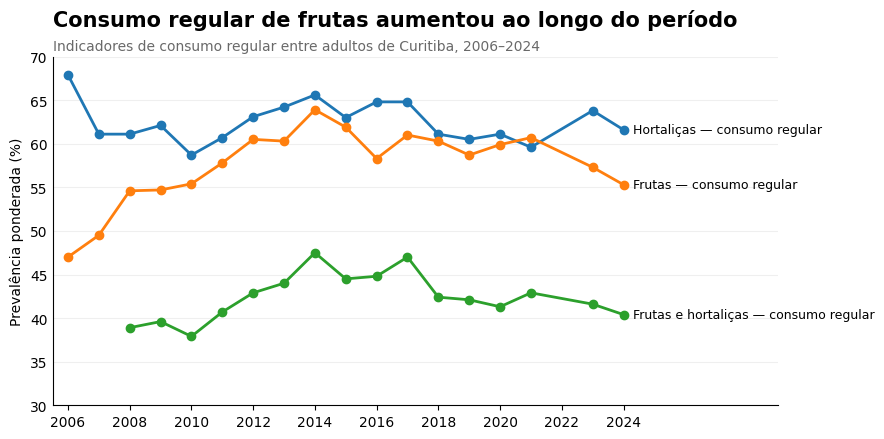

In [ ]:
# Selecionar apenas indicadores de consumo regular
indicadores_regulares = {
    'Hortaliças — consumo regular': bloco_frutas_hortalicas['Hortaliças regularmente'],
    'Frutas — consumo regular': bloco_frutas_hortalicas['Frutas regularmente'],
    'Frutas e hortaliças — consumo regular': bloco_frutas_hortalicas['Frutas e hortaliças regularmente']
}

fig, ax = plt.subplots(figsize=(9, 4.5))

for nome, serie in indicadores_regulares.items():
    serie = serie.dropna()

    ax.plot(
        serie.index,
        serie.values,
        marker='o',
        linewidth=2,
        label=nome
    )

    # Rótulo diretamente no final da linha
    ax.text(
        serie.index[-1] + 0.3,
        serie.iloc[-1],
        nome,
        va='center',
        fontsize=9
    )

# Título e subtítulo
ax.set_title(
    'Consumo regular de frutas aumentou ao longo do período',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Indicadores de consumo regular entre adultos de Curitiba, 2006–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xticks(range(2006, 2025, 2))

# Mesma escala para todos os indicadores
ax.set_ylim(30, 70)

# Espaço para os rótulos
ax.set_xlim(2005.5, 2029)

# Simplificar o visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

### Consumo recomendado de frutas e hortaliças

O indicador de consumo recomendado utiliza um critério mais restritivo do que os indicadores de consumo regular apresentados anteriormente. Por isso, sua evolução é apresentada separadamente.

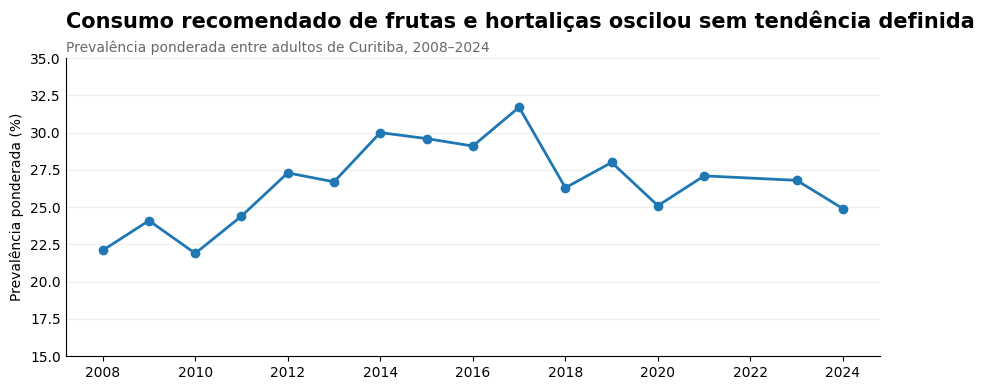

In [ ]:
# Selecionar o indicador
serie_recomendado = bloco_frutas_hortalicas[
    'Consumo recomendado de frutas e hortaliças'
].dropna()

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    serie_recomendado.index,
    serie_recomendado.values,
    marker='o',
    linewidth=2
)

# Título e subtítulo
ax.set_title(
    'Consumo recomendado de frutas e hortaliças oscilou sem tendência definida',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2008–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xticks(range(2008, 2025, 2))

# Escala adequada ao indicador
ax.set_ylim(15, 35)

# Simplificar o visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

### 2.2 Consumo regular de feijão

In [ ]:
# BLOCO 2 — Consumo regular de feijão

# Selecionar a série histórica
feijao = tabela_prevalencias[['feijao5']].copy()

# Renomear a coluna para facilitar a leitura
feijao = feijao.rename(
    columns={'feijao5': 'Feijão regularmente'}
)

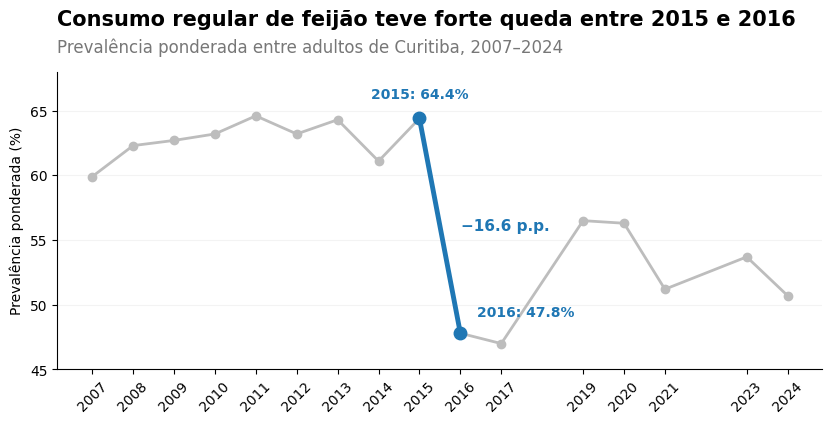

In [ ]:
# Preparar os dados
feijao_grafico = feijao.dropna()

coluna = 'Feijão regularmente'

valor_2015 = feijao_grafico.loc[2015, coluna]
valor_2016 = feijao_grafico.loc[2016, coluna]

fig, ax = plt.subplots(figsize=(9, 4.8))

# Série histórica em cinza
ax.plot(
    feijao_grafico.index,
    feijao_grafico[coluna],
    color='#BDBDBD',
    linewidth=2,
    marker='o',
    markersize=6,
    zorder=2
)

# Destacar a queda entre 2015 e 2016
ax.plot(
    [2015, 2016],
    [valor_2015, valor_2016],
    color='#1f77b4',
    linewidth=3.5,
    marker='o',
    markersize=9,
    zorder=4
)

# Rótulo de 2015 acima do ponto
ax.annotate(
    f'2015: {valor_2015:.1f}%',
    xy=(2015, valor_2015),
    xytext=(0, 12),
    textcoords='offset points',
    ha='center',
    va='bottom',
    fontsize=10,
    fontweight='bold',
    color='#1f77b4'
)

# Rótulo de 2016 acima e à direita do ponto
ax.annotate(
    f'2016: {valor_2016:.1f}%',
    xy=(2016, valor_2016),
    xytext=(12, 12),
    textcoords='offset points',
    ha='left',
    fontsize=10,
    fontweight='bold',
    color='#1f77b4'
)

# Destacar a redução em pontos percentuais
queda = valor_2016 - valor_2015

ax.annotate(
    f'{queda:.1f} p.p.'.replace('-', '−'),
    xy=(2015.5, (valor_2015 + valor_2016) / 2),
    xytext=(15, 0),
    textcoords='offset points',
    fontsize=11,
    fontweight='bold',
    color='#1f77b4',
    va='center'
)

# Título
fig.suptitle(
    'Consumo regular de feijão teve forte queda entre 2015 e 2016',
    fontsize=15,
    fontweight='bold',
    x=0.12,
    ha='left',
    y=0.93
)

# Subtítulo
ax.set_title(
    'Prevalência ponderada entre adultos de Curitiba, 2007–2024',
    loc='left',
    fontsize=12,
    color='#777777',
    pad=14
)

# Eixos
ax.set_ylabel(
    'Prevalência ponderada (%)',
    fontsize=10
)

ax.set_xticks(feijao_grafico.index)
ax.tick_params(axis='x', rotation=45)

ax.set_ylim(45, 68)

# Limpeza visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.15)

# Espaçamento
fig.subplots_adjust(
    top=0.80,
    bottom=0.18,
    left=0.12,
    right=0.97
)

plt.show()

In [ ]:
# Calcular tendência linear do consumo regular de feijão

serie = feijao['Feijão regularmente'].dropna()

resultado_feijao = linregress(
    serie.index.astype(float),
    serie.values
)

print(f"Nº de anos analisados: {len(serie)}")
print(f"Variação média anual: {resultado_feijao.slope:.3f} p.p./ano")
print(f"P-valor: {resultado_feijao.pvalue:.3f}")
print(f"R²: {resultado_feijao.rvalue**2:.3f}")

Nº de anos analisados: 16
Variação média anual: -0.800 p.p./ano
P-valor: 0.003
R²: 0.475


O consumo regular de feijão apresentou **tendência de queda** no período analisado, com redução média estimada de **0,8 ponto percentual por ano** (p = 0,003; R² = 0,475).

A série também mostra uma queda acentuada entre **2015 e 2016**, que será investigada com maior profundidade no **Notebook 02 — Investigação sociológica**.

### 2.3 Consumo regular de refrigerantes

In [ ]:
refrigerante = tabela_prevalencias[['refritl5']].copy()

refrigerante = refrigerante.rename(
    columns={'refritl5': 'Consumo regular de refrigerantes'}
)

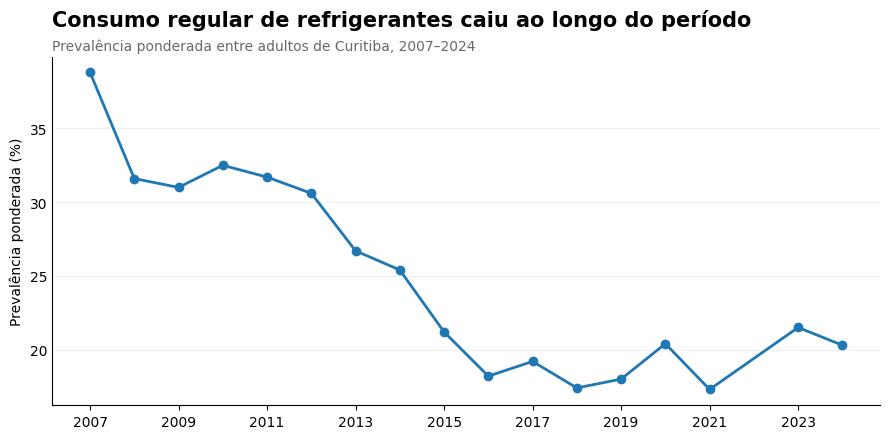

In [ ]:
# Remover somente os anos sem informação
refrigerante_grafico = refrigerante.dropna()

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    refrigerante_grafico.index,
    refrigerante_grafico['Consumo regular de refrigerantes'],
    marker='o',
    linewidth=2
)

ax.set_title(
    'Consumo regular de refrigerantes caiu ao longo do período',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2007–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('')

ax.set_xticks(list(range(2007, 2024, 2)))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

In [ ]:
# Remover anos sem informação
serie_refri = refrigerante[
    'Consumo regular de refrigerantes'
].dropna()

# Regressão linear
resultado_refri = linregress(
    serie_refri.index.astype(float),
    serie_refri.values
)

print(f"Número de anos: {len(serie_refri)}")
print(f"Variação média anual (β): {resultado_refri.slope:.3f} p.p./ano")
print(f"p-valor: {resultado_refri.pvalue:.3f}")
print(f"R²: {resultado_refri.rvalue**2:.3f}")

Número de anos: 17
Variação média anual (β): -1.105 p.p./ano
p-valor: 0.000
R²: 0.745


O consumo regular de refrigerantes apresentou **tendência de queda** no período analisado, com redução média estimada de **1,1 ponto percentual por ano** (p < 0,001; R² = 0,745).

A redução foi mais acentuada nos primeiros anos da série, seguida por oscilações e maior estabilidade nos anos mais recentes. Portanto, a tendência linear resume a direção geral do período, mas não significa que a redução tenha ocorrido no mesmo ritmo em todos os anos.

### 2.4 Consumo regular de doces

In [ ]:
doces = tabela_prevalencias[['doces5']].dropna().copy()

doces = doces.rename(
    columns={'doces5': 'Consumo regular de doces'}
)

display(doces.round(1))

Indicador,Consumo regular de doces
Ano,
2012,23.3
2013,24.1
2014,22.3
2015,21.0
2016,23.8


Consumo regular de doces. Entre 2012 e 2016, a prevalência variou entre 21,0% e 24,1%, sem uma direção consistente de aumento ou redução no curto período disponível. Por esse motivo, o indicador é apresentado apenas de forma descritiva.

### 2.5 Consumo de carnes com excesso de gordura

O indicador de consumo de carnes com excesso de gordura combina o consumo de carne vermelha com gordura visível e de frango com pele. Por isso, ele foi utilizado como indicador principal nesta análise, evitando tratar seus componentes separadamente.

In [ ]:
gordura = tabela_prevalencias[['gordura']].copy()

gordura = gordura.rename(
    columns={'gordura': 'Consumo de carnes com excesso de gordura'}
)

display(gordura.round(1))

Indicador,Consumo de carnes com excesso de gordura
Ano,
2006,NaN
2007,35.2
2008,33.1
2009,37.3
2010,36.8
2011,34.4
2012,32.3
2013,31.8
2014,32.3


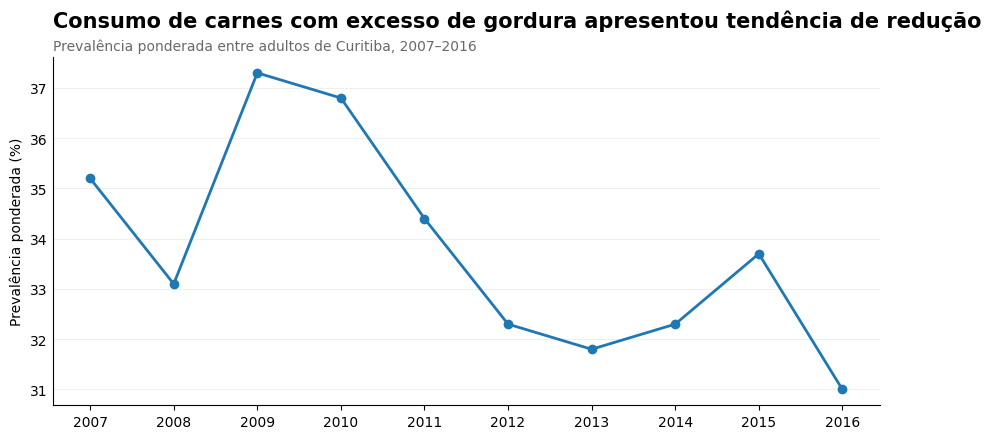

In [ ]:
gordura_grafico = gordura.dropna()

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    gordura_grafico.index,
    gordura_grafico['Consumo de carnes com excesso de gordura'],
    marker='o',
    linewidth=2
)

ax.set_title(
    'Consumo de carnes com excesso de gordura apresentou tendência de redução',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2007–2016',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('')

ax.set_xticks(gordura_grafico.index)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

In [ ]:
# Recriar a variável gordura caso a célula anterior não tenha sido executada
gordura = tabela_prevalencias[['gordura']].copy()
gordura = gordura.rename(
    columns={'gordura': 'Consumo de carnes com excesso de gordura'}
)

# Definir a série histórica removendo os valores ausentes
gordura_serie = gordura['Consumo de carnes com excesso de gordura'].dropna()

# Analisar a tendência linear
resultado_gordura = linregress(
    gordura_serie.index.astype(float),
    gordura_serie.values
)

print(f"Número de anos: {len(gordura_serie)}")
print(f"Variação média anual (β): {resultado_gordura.slope:.3f} p.p./ano")
print(f"p-valor: {resultado_gordura.pvalue:.3f}")
print(f"R²: {resultado_gordura.rvalue**2:.3f}")

Número de anos: 10
Variação média anual (β): -0.459 p.p./ano
p-valor: 0.040
R²: 0.430


Entre 2007 e 2016, Curitiba apresentou tendência estatisticamente significativa de redução do consumo de carnes com excesso de gordura (β = -0,459 p.p./ano; p = 0,040; R² = 0,430).

### 2.6 Consumo de leite integral

In [ ]:
leite = tabela_prevalencias[['leiteint']].copy()

leite = leite.rename(
    columns={'leiteint': 'Consumo de leite integral'}
)

display(leite.round(1))

Indicador,Consumo de leite integral
Ano,
2006,NaN
2007,59.7
2008,60.5
2009,63.6
2010,59.2
2011,59.0
2012,56.7
2013,56.5
2014,54.2


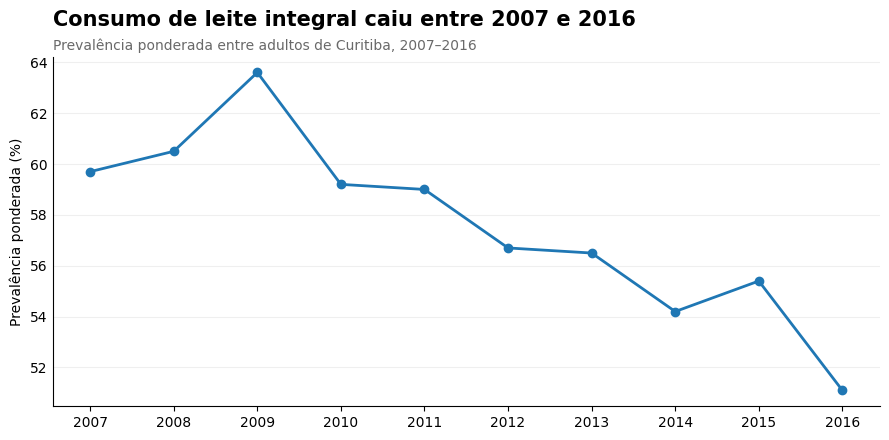

In [ ]:
# Filtrar os anos válidos para o indicador
leite_grafico = leite.dropna()

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    leite_grafico.index,
    leite_grafico['Consumo de leite integral'],
    marker='o',
    linewidth=2
)

ax.set_title(
    'Consumo de leite integral caiu entre 2007 e 2016',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2007–2016',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('')

# Definir marcas exatas de anos com dados
ax.set_xticks(leite_grafico.index)

# Simplificar o visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

In [ ]:
# Remover anos sem informação
serie_leite = leite[
    'Consumo de leite integral'
].dropna()

# Regressão linear
resultado_leite = linregress(
    serie_leite.index.astype(float),
    serie_leite.values
)

print(f"Número de anos: {len(serie_leite)}")
print(f"Variação média anual (β): {resultado_leite.slope:.3f} p.p./ano")
print(f"p-valor: {resultado_leite.pvalue:.3f}")
print(f"R²: {resultado_leite.rvalue**2:.3f}")

Número de anos: 10
Variação média anual (β): -1.033 p.p./ano
p-valor: 0.001
R²: 0.773


Entre 2007 e 2016, Curitiba apresentou tendência estatisticamente significativa de redução do consumo de leite integral (β = -1,033 p.p./ano; p = 0,001; R² = 0,773).

###2.7 Substituição de refeições por lanches

In [ ]:
lanches = tabela_prevalencias[['lanche_7']].copy()

lanches = lanches.rename(
    columns={
        'lanche_7': 'Substituição de refeições por lanches'
    }
)

display(lanches.round(1))

Indicador,Substituição de refeições por lanches
Ano,
2006,NaN
2007,NaN
2008,NaN
2009,NaN
2010,NaN
2011,NaN
2012,NaN
2013,20.7
2014,24.4


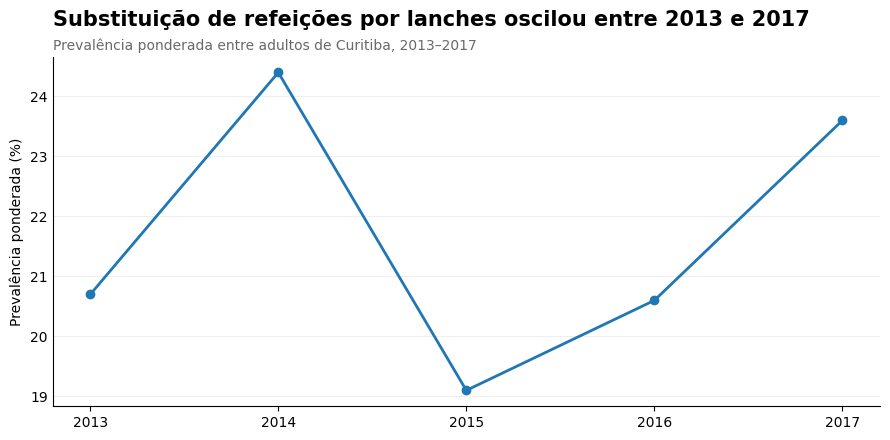

In [ ]:
# Manter apenas os anos com dados disponíveis
serie_lanches = lanches['Substituição de refeições por lanches'].dropna()

# Criar o gráfico
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    serie_lanches.index,
    serie_lanches.values,
    marker='o',
    linewidth=2
)

ax.set_title(
    'Substituição de refeições por lanches oscilou entre 2013 e 2017',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2013–2017',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xticks(serie_lanches.index)

# Simplificar o visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

Entre 2013 e 2017, a prevalência de substituição regular das refeições principais por lanches em Curitiba oscilou entre 19,1% e 24,4%, sem apresentar uma direção consistente de aumento ou redução no período disponível.

###2.8 Percepção de consumo de sal alto ou muito alto

In [ ]:
sal = tabela_prevalencias[['sal']].copy()

sal = sal.rename(
    columns={'sal': 'Percepção de consumo de sal alto ou muito alto'}
)

display(sal.dropna().round(1))

Indicador,Percepção de consumo de sal alto ou muito alto
Ano,
2013,18.1
2014,17.9
2015,18.8


Entre 2013 e 2015, a proporção de adultos de Curitiba que referiram perceber seu consumo de sal como alto ou muito alto permaneceu próxima de 18%, variando entre 17,9% e 18,8%. Devido ao curto período disponível, o indicador foi analisado apenas de forma descritiva.

###2.9 Indicadores de qualidade global da alimentação

In [ ]:
scores = tabela_prevalencias[
    ['score_sf_2cat', 'score_upp_2cat', 'score_upp_2cat2024']
].copy()

scores = scores.rename(
    columns={
        'score_sf_2cat': '5+ grupos de alimentos não ou minimamente processados',
        'score_upp_2cat': '5+ grupos de alimentos ultraprocessados',
        'score_upp_2cat2024': 'Ultraprocessados — indicador 2024'
    }
)

display(scores.dropna(how='all').round(1))

Indicador,5+ grupos de alimentos não ou minimamente processados,5+ grupos de alimentos ultraprocessados,Ultraprocessados — indicador 2024
Ano,,,
2018,29.1,21.1,NaN
2019,31.8,21.4,NaN
2020,31.9,23.0,NaN
2021,31.6,25.3,NaN
2023,34.1,22.4,NaN
2024,NaN,NaN,28.0


Os indicadores de consumo de cinco ou mais grupos de alimentos não ou minimamente processados e de ultraprocessados estão disponíveis de forma comparável entre 2018 e 2023. Em 2024, a construção do indicador de ultraprocessados foi modificada; por isso, esse valor é apresentado separadamente e não foi incorporado à série anterior.

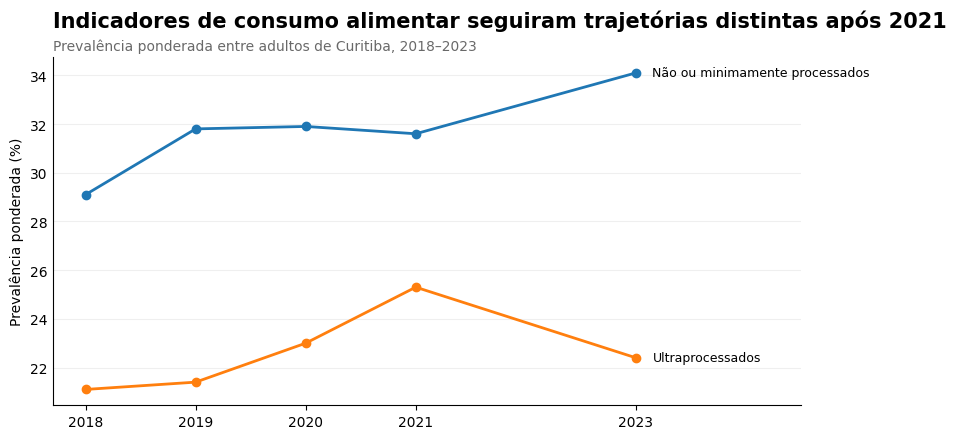

In [ ]:
# Gráfico — alimentos não/minimamente processados e ultraprocessados

scores_comparaveis = scores[
    [
        '5+ grupos de alimentos não ou minimamente processados',
        '5+ grupos de alimentos ultraprocessados'
    ]
].dropna()

fig, ax = plt.subplots(figsize=(9, 4.5))

# Séries
ax.plot(
    scores_comparaveis.index,
    scores_comparaveis[
        '5+ grupos de alimentos não ou minimamente processados'
    ],
    marker='o',
    linewidth=2
)

ax.plot(
    scores_comparaveis.index,
    scores_comparaveis[
        '5+ grupos de alimentos ultraprocessados'
    ],
    marker='o',
    linewidth=2
)

# Título
ax.set_title(
    'Indicadores de consumo alimentar seguiram trajetórias distintas após 2021',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

# Subtítulo
ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2018–2023',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

# Identificar as linhas diretamente
ax.text(
    2023.15,
    scores_comparaveis.iloc[-1, 0],
    'Não ou minimamente processados',
    va='center',
    fontsize=9
)

ax.text(
    2023.15,
    scores_comparaveis.iloc[-1, 1],
    'Ultraprocessados',
    va='center',
    fontsize=9
)

# Eixos
ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xticks(scores_comparaveis.index)
ax.set_xlim(2017.7, 2024.5)

# Simplificar o visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

Entre 2018 e 2023, a prevalência do consumo de cinco ou mais grupos de alimentos não ou minimamente processados aumentou de 29,1% para 34,1% em Curitiba. No mesmo período, o consumo de cinco ou mais grupos de ultraprocessados aumentou de 21,1% em 2018 para 25,3% em 2021, recuando para 22,4% em 2023. Devido ao número reduzido de anos disponíveis, os resultados foram analisados de forma descritiva.
Em 2024, o novo indicador de consumo de ultraprocessados apresentou prevalência de 28,0%. Como houve alteração na construção do indicador, esse resultado foi mantido separado da série de 2018–2023.

###2.10 Síntese da análise temporal dos indicadores alimentares

In [ ]:
tabela_sintese = pd.DataFrame([
    {
        'Indicador': 'Hortaliças regularmente',
        'Período': '2006–2024',
        'Análise': 'Tendência linear',
        'Resultado': 'Sem tendência linear significativa'
    },
    {
        'Indicador': 'Frutas regularmente',
        'Período': '2006–2024',
        'Análise': 'Tendência linear',
        'Resultado': 'Tendência de aumento'
    },
    {
        'Indicador': 'Frutas e hortaliças regularmente',
        'Período': '2008–2024',
        'Análise': 'Tendência linear',
        'Resultado': 'Sem tendência linear significativa'
    },
    {
        'Indicador': 'Consumo recomendado de frutas e hortaliças',
        'Período': '2008–2024',
        'Análise': 'Tendência linear',
        'Resultado': 'Sem tendência linear significativa'
    },
    {
        'Indicador': 'Consumo regular de feijão',
        'Período': '2007–2024',
        'Análise': 'Tendência linear',
        'Resultado': 'Tendência de redução'
    },
    {
        'Indicador': 'Consumo regular de refrigerantes',
        'Período': '2007–2024',
        'Análise': 'Tendência linear',
        'Resultado': 'Tendência de redução'
    },
    {
        'Indicador': 'Consumo regular de doces',
        'Período': '2012–2016',
        'Análise': 'Descritiva',
        'Resultado': 'Oscilações sem direção consistente'
    },
    {
        'Indicador': 'Carnes com excesso de gordura',
        'Período': '2007–2016',
        'Análise': 'Tendência linear',
        'Resultado': 'Tendência de redução'
    },
    {
        'Indicador': 'Consumo de leite integral',
        'Período': '2007–2016',
        'Análise': 'Tendência linear',
        'Resultado': 'Tendência de redução'
    },
    {
        'Indicador': 'Substituição regular de refeições por lanches',
        'Período': '2013–2017',
        'Análise': 'Descritiva',
        'Resultado': 'Oscilações sem direção consistente'
    },
    {
        'Indicador': 'Percepção de consumo de sal alto ou muito alto',
        'Período': '2013–2015',
        'Análise': 'Descritiva',
        'Resultado': 'Valores próximos de 18%'
    },
    {
        'Indicador': '5+ grupos de alimentos não ou minimamente processados',
        'Período': '2018–2023',
        'Análise': 'Descritiva',
        'Resultado': 'Aumento de 29,1% para 34,1%'
    },
    {
        'Indicador': '5+ grupos de alimentos ultraprocessados',
        'Período': '2018–2023',
        'Análise': 'Descritiva',
        'Resultado': 'Aumento até 2021, seguido de redução em 2023'
    },
    {
        'Indicador': 'Ultraprocessados — indicador 2024',
        'Período': '2024',
        'Análise': 'Descritiva',
        'Resultado': '28,0%; não comparável diretamente à série anterior'
    }
])

display(tabela_sintese)

,Indicador,Período,Análise,Resultado
0,Hortaliças regularmente,2006–2024,Tendência linear,Sem tendência linear significativa
1,Frutas regularmente,2006–2024,Tendência linear,Tendência de aumento
2,Frutas e hortaliças regularmente,2008–2024,Tendência linear,Sem tendência linear significativa
3,Consumo recomendado de frutas e hortaliças,2008–2024,Tendência linear,Sem tendência linear significativa
4,Consumo regular de feijão,2007–2024,Tendência linear,Tendência de redução
5,Consumo regular de refrigerantes,2007–2024,Tendência linear,Tendência de redução
6,Consumo regular de doces,2012–2016,Descritiva,Oscilações sem direção consistente
7,Carnes com excesso de gordura,2007–2016,Tendência linear,Tendência de redução
8,Consumo de leite integral,2007–2016,Tendência linear,Tendência de redução
9,Substituição regular de refeições por lanches,2013–2017,Descritiva,Oscilações sem direção consistente


In [ ]:
# Selecionar os indicadores para a síntese visual
indicadores_grafico = {
    'frutareg': 'Frutas',
    'feijao5': 'Feijão',
    'refritl5': 'Refrigerantes',
    'flvreco': 'Frutas e hortaliças — recomendado'
}

grafico_sintese = tabela_prevalencias[
    list(indicadores_grafico.keys())
].rename(columns=indicadores_grafico)

display(grafico_sintese)

Indicador,Frutas,Feijão,Refrigerantes,Frutas e hortaliças — recomendado
Ano,,,,
2006,47.0,NaN,NaN,NaN
2007,49.5,59.9,38.8,NaN
2008,54.6,62.3,31.6,22.1
2009,54.7,62.7,31.0,24.1
2010,55.4,63.2,32.5,21.9
2011,57.8,64.6,31.7,24.4
2012,60.5,63.2,30.6,27.3
2013,60.3,64.3,26.7,26.7
2014,63.9,61.1,25.4,30.0


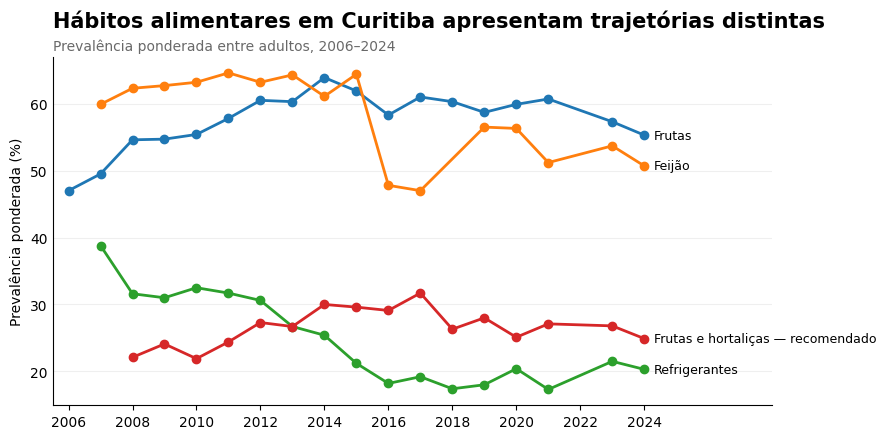

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))

for indicador in grafico_sintese.columns:
    serie = grafico_sintese[indicador].dropna()

    ax.plot(
        serie.index,
        serie.values,
        marker='o',
        linewidth=2,
        label=indicador
    )

ax.set_title(
    'Hábitos alimentares em Curitiba apresentam trajetórias distintas',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos, 2006–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('Ano')

ax.set_xticks(range(2006, 2025, 2))

# Identificar as séries diretamente no gráfico
for indicador in grafico_sintese.columns:
    serie = grafico_sintese[indicador].dropna()

    ax.text(
        serie.index[-1] + 0.3,
        serie.iloc[-1],
        indicador,
        va='center',
        fontsize=9
    )

# Criar espaço à direita para os rótulos
ax.set_xlim(2005.5, 2028)

# Simplificar o visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Grade horizontal discreta
ax.grid(axis='y', alpha=0.2)

# Remover marcas do eixo Y
ax.tick_params(axis='y', length=0)

# Retirar o título do eixo X
ax.set_xlabel('')

plt.tight_layout()
plt.show()

###Síntese dos resultados

A análise temporal mostra que as mudanças nos hábitos alimentares da população adulta de Curitiba não ocorreram de maneira uniforme. O consumo regular de frutas apresentou tendência de aumento, enquanto o consumo regular de feijão, refrigerantes, carnes com excesso de gordura e leite integral apresentou tendência de redução nos respectivos períodos analisados. Outros indicadores não apresentaram tendência linear significativa ou, devido ao número reduzido de anos disponíveis, foram analisados apenas de forma descritiva.
Os resultados também revelaram mudanças específicas que merecem investigação mais aprofundada, especialmente a queda do consumo regular de feijão e as alterações observadas nos indicadores de ultraprocessados. Essas questões serão retomadas posteriormente em diálogo com o contexto social e econômico.

## 3. Frequência diária de consumo de frutas e hortaliças

Além dos indicadores de prevalência, o Vigitel disponibiliza variáveis que representam a frequência diária de consumo de frutas e hortaliças. Nesta seção, são analisados três indicadores: frequência diária de consumo de hortaliças, de frutas e o indicador agregado de frutas e hortaliças.

In [ ]:
# Indicadores quantitativos de frequência diária
indicadores_quantitativos = [
    'cruadia',
    'cozidadia',
    'hortadia',
    'sucodia',
    'sofrutadia',
    'frutadia',
    'flvdia'
]

# Função para calcular média ponderada
def media_ponderada(grupo, indicador):
    dados_validos = grupo[[indicador, 'pesorake2025']].dropna()

    if len(dados_validos) == 0:
        return float('nan')

    return (
        (dados_validos[indicador] * dados_validos['pesorake2025']).sum()
        / dados_validos['pesorake2025'].sum()
    )

# Calcula a média ponderada de cada indicador por ano
resultados_quantitativos = []

for indicador in indicadores_quantitativos:
    for ano, grupo in curitiba.groupby('ano'):

        media = media_ponderada(grupo, indicador)

        resultados_quantitativos.append({
            'Ano': ano,
            'Indicador': indicador,
            'Média ponderada': media
        })

resultados_quantitativos = pd.DataFrame(resultados_quantitativos)

# Organiza os resultados em formato de tabela
tabela_quantitativos = resultados_quantitativos.pivot(
    index='Ano',
    columns='Indicador',
    values='Média ponderada'
).round(2)


### 3.1 Evolução dos indicadores

Para facilitar a interpretação, foram selecionados os três indicadores agregados de frequência diária: hortaliças, frutas e frutas e hortaliças.

In [ ]:
# Selecionar os indicadores quantitativos principais
indicadores_quantitativos_principais = [
    'hortadia',
    'frutadia',
    'flvdia'
]

tabela_quantitativos_principais = (
    resultados_quantitativos[
        resultados_quantitativos['Indicador'].isin(
            indicadores_quantitativos_principais
        )
    ]
    .pivot(
        index='Ano',
        columns='Indicador',
        values='Média ponderada'
    )
    .rename(columns={
        'hortadia': 'Hortaliças/dia',
        'frutadia': 'Frutas/dia',
        'flvdia': 'Frutas e hortaliças/dia'
    })
    .round(2)
)

display(tabela_quantitativos_principais)

Indicador,Frutas e hortaliças/dia,Frutas/dia,Hortaliças/dia
Ano,,,
2006,2.02,0.80,1.23
2007,3.48,1.37,2.12
2008,4.09,1.97,2.11
2009,4.25,2.06,2.20
2010,4.26,2.06,2.19
2011,4.32,2.12,2.20
2012,4.40,2.14,2.26
2013,4.44,2.11,2.33
2014,4.50,2.23,2.27


In [ ]:
# Análise de tendência dos indicadores de frequência diária
# Período comparável: 2009–2024

resultados_regressao_quantitativos = []

for indicador in indicadores_quantitativos_principais:

    df_temp = resultados_quantitativos[
        (resultados_quantitativos['Indicador'] == indicador) &
        (resultados_quantitativos['Ano'] >= 2009)
    ].dropna(subset=['Média ponderada'])

    regressao = linregress(
        df_temp['Ano'],
        df_temp['Média ponderada']
    )

    resultados_regressao_quantitativos.append({
        'Indicador': indicador,
        'Nº de anos': len(df_temp),
        'β (unidades/ano)': regressao.slope,
        'p-valor': regressao.pvalue,
        'R²': regressao.rvalue ** 2
    })

tabela_regressao_quantitativos = pd.DataFrame(
    resultados_regressao_quantitativos
)

tabela_regressao_quantitativos['Indicador'] = (
    tabela_regressao_quantitativos['Indicador'].replace({
        'hortadia': 'Hortaliças/dia',
        'frutadia': 'Frutas/dia',
        'flvdia': 'Frutas e hortaliças/dia'
    })
)

display(tabela_regressao_quantitativos.round(3))

,Indicador,Nº de anos,β (unidades/ano),p-valor,R²
0,Hortaliças/dia,15,0.011,0.000,0.698
1,Frutas/dia,15,0.002,0.620,0.019
2,Frutas e hortaliças/dia,15,0.013,0.018,0.363


###Resultados

Considerando o período comparável de 2009 a 2024, a frequência diária de consumo de hortaliças apresentou tendência significativa de aumento (β = 0,011 unidade/ano; p < 0,001; R² = 0,698). O indicador agregado de frutas e hortaliças também apresentou tendência significativa de aumento (β = 0,013 unidade/ano; p = 0,018; R² = 0,363).
Já a frequência diária de consumo de frutas permaneceu relativamente estável, sem tendência linear estatisticamente significativa (β = 0,002 unidade/ano; p = 0,620; R² = 0,019).
Assim, o aumento observado no indicador agregado de frutas e hortaliças parece estar associado principalmente ao crescimento da frequência de consumo de hortaliças.

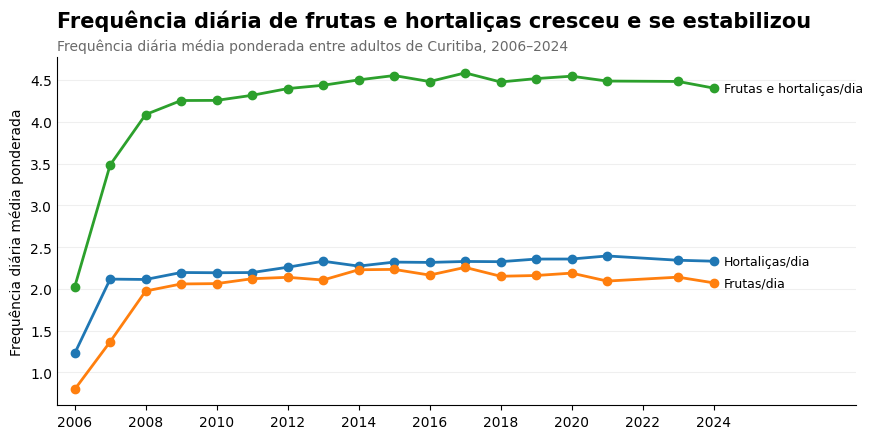

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))

nomes = {
    'hortadia': 'Hortaliças/dia',
    'frutadia': 'Frutas/dia',
    'flvdia': 'Frutas e hortaliças/dia'
}

for indicador, nome in nomes.items():

    df_temp = resultados_quantitativos[
        resultados_quantitativos['Indicador'] == indicador
    ].dropna(subset=['Média ponderada'])

    ax.plot(
        df_temp['Ano'],
        df_temp['Média ponderada'],
        marker='o',
        linewidth=2
    )

    # Rótulo diretamente no final da linha
    ax.text(
        df_temp['Ano'].iloc[-1] + 0.3,
        df_temp['Média ponderada'].iloc[-1],
        nome,
        va='center',
        fontsize=9
    )

ax.set_title(
    'Frequência diária de frutas e hortaliças cresceu e se estabilizou',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Frequência diária média ponderada entre adultos de Curitiba, 2006–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Frequência diária média ponderada')
ax.set_xlabel('')

ax.set_xticks(range(2006, 2025, 2))

# Espaço para os rótulos à direita
ax.set_xlim(2005.5, 2028)

# Simplificar o visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

### Definição do período comparável

A análise inicial considerou o período de 2006 a 2024 e indicou tendências significativas de aumento nos três indicadores quantitativos. Entretanto, a inspeção das séries revelou variações acentuadas nos primeiros anos.

A verificação da construção e da disponibilidade das variáveis mostrou que alguns componentes dos indicadores agregados não estavam disponíveis em todas as edições iniciais: `sucodia` passa a estar disponível em 2008 e `cozidadia` em 2009. A partir de 2009, todos os componentes utilizados na construção de `hortadia`, `frutadia` e `flvdia` estão disponíveis.

Por esse motivo, adotou-se 2009–2024 como período comparável para a análise de tendência desses indicadores, reduzindo o risco de interpretar diferenças na composição das variáveis como mudanças nos hábitos alimentares.

In [ ]:
# Regressão dos indicadores quantitativos no período comparável (2009–2024)

resultados_regressao_quantitativos_comparaveis = []

for indicador in indicadores_quantitativos_principais:

    df_temp = resultados_quantitativos[
        (resultados_quantitativos['Indicador'] == indicador) &
        (resultados_quantitativos['Ano'] >= 2009)
    ].dropna(subset=['Média ponderada'])

    regressao = linregress(
        df_temp['Ano'],
        df_temp['Média ponderada']
    )

    resultados_regressao_quantitativos_comparaveis.append({
        'Indicador': indicador,
        'Período': '2009–2024',
        'Nº de anos': len(df_temp),
        'β (unidades/ano)': regressao.slope,
        'p-valor': regressao.pvalue,
        'R²': regressao.rvalue ** 2
    })

tabela_regressao_quantitativos_comparaveis = pd.DataFrame(
    resultados_regressao_quantitativos_comparaveis
)

tabela_regressao_quantitativos_comparaveis[
    ['β (unidades/ano)', 'p-valor', 'R²']
] = tabela_regressao_quantitativos_comparaveis[
    ['β (unidades/ano)', 'p-valor', 'R²']
].round(4)

display(tabela_regressao_quantitativos_comparaveis)

,Indicador,Período,Nº de anos,β (unidades/ano),p-valor,R²
0,hortadia,2009–2024,15,0.0114,0.0001,0.6977
1,frutadia,2009–2024,15,0.0018,0.6203,0.0194
2,flvdia,2009–2024,15,0.0132,0.0175,0.3627


### Resultados dos indicadores quantitativos

Considerando o período comparável de 2009 a 2024, foram identificadas tendências distintas nos três indicadores de frequência diária.

A frequência diária de consumo de hortaliças apresentou tendência significativa de aumento (β = 0,011 unidade/ano; p < 0,001; R² = 0,698). O indicador agregado de frutas e hortaliças também apresentou tendência significativa de aumento (β = 0,013 unidade/ano; p = 0,018; R² = 0,363).

Para a frequência diária de consumo de frutas, não foi identificada tendência linear estatisticamente significativa (β = 0,002 unidade/ano; p = 0,620; R² = 0,019).
Assim, o aumento observado no indicador agregado de frutas e hortaliças parece estar relacionado principalmente ao crescimento da frequência diária de consumo de hortaliças.

In [ ]:
# Tabela-síntese final da análise temporal

tabela_sintese = pd.DataFrame([
    ['Hortaliças regularmente', '2006–2024', 'Regressão linear',
     -0.067, 'p.p./ano', 0.531, 0.025, 'Sem tendência linear significativa'],

    ['Frutas regularmente', '2006–2024', 'Regressão linear',
     0.416, 'p.p./ano', 0.023, 0.285, 'Tendência significativa de aumento'],

    ['Frutas e hortaliças regularmente', '2008–2024', 'Regressão linear',
     0.120, 'p.p./ano', 0.413, 0.048, 'Sem tendência linear significativa'],

    ['Consumo recomendado de frutas e hortaliças', '2008–2024', 'Regressão linear',
     0.196, 'p.p./ano', 0.179, 0.125, 'Sem tendência linear significativa'],

    ['Consumo regular de feijão', '2007–2024', 'Regressão linear',
     -0.800, 'p.p./ano', 0.003, 0.475, 'Tendência significativa de redução'],

    ['Consumo regular de refrigerantes', '2007–2024', 'Regressão linear',
     -1.105, 'p.p./ano', '<0,001', 0.745, 'Tendência significativa de redução'],

    ['Consumo regular de doces', '2012–2016', 'Descritiva',
     None, '-', None, None, 'Oscilação sem direção consistente'],

    ['Carnes com excesso de gordura', '2007–2016', 'Regressão linear',
     -0.459, 'p.p./ano', 0.040, 0.430, 'Tendência significativa de redução'],

    ['Consumo de leite integral', '2007–2016', 'Regressão linear',
     -1.033, 'p.p./ano', 0.001, 0.773, 'Tendência significativa de redução'],

    ['Substituição regular de refeições por lanches', '2013–2017', 'Descritiva',
     None, '-', None, None, 'Oscilação sem direção consistente'],

    ['Percepção de consumo de sal alto ou muito alto', '2013–2015', 'Descritiva',
     None, '-', None, None, 'Valores próximos de 18% no período'],

    ['5+ grupos de alimentos não ou minimamente processados', '2018–2023', 'Descritiva',
     None, '-', None, None, 'Aumento de 29,1% para 34,1%'],

    ['5+ grupos de alimentos ultraprocessados', '2018–2023', 'Descritiva',
     None, '-', None, None, 'Oscilação; pico de 25,3% em 2021'],

    ['Novo score de ultraprocessados', '2024', 'Descritiva',
     None, '-', None, None, '28,0%; não comparável diretamente à série anterior'],

    ['Frequência diária de consumo de hortaliças', '2009–2024', 'Regressão linear',
     0.011, 'unidades/ano', '<0,001', 0.698, 'Tendência significativa de aumento'],

    ['Frequência diária de consumo de frutas', '2009–2024', 'Regressão linear',
     0.002, 'unidades/ano', 0.620, 0.019, 'Sem tendência linear significativa'],

    ['Frequência diária de consumo de frutas e hortaliças', '2009–2024', 'Regressão linear',
     0.013, 'unidades/ano', 0.018, 0.363, 'Tendência significativa de aumento']
],
columns=[
    'Indicador',
    'Período',
    'Tipo de análise',
    'β',
    'Unidade do β',
    'p-valor',
    'R²',
    'Resultado'
])

display(tabela_sintese)

,Indicador,Período,Tipo de análise,β,Unidade do β,p-valor,R²,Resultado
0,Hortaliças regularmente,2006–2024,Regressão linear,-0.067,p.p./ano,0.531,0.025,Sem tendência linear significativa
1,Frutas regularmente,2006–2024,Regressão linear,0.416,p.p./ano,0.023,0.285,Tendência significativa de aumento
2,Frutas e hortaliças regularmente,2008–2024,Regressão linear,0.120,p.p./ano,0.413,0.048,Sem tendência linear significativa
3,Consumo recomendado de frutas e hortaliças,2008–2024,Regressão linear,0.196,p.p./ano,0.179,0.125,Sem tendência linear significativa
4,Consumo regular de feijão,2007–2024,Regressão linear,-0.800,p.p./ano,0.003,0.475,Tendência significativa de redução
5,Consumo regular de refrigerantes,2007–2024,Regressão linear,-1.105,p.p./ano,"<0,001",0.745,Tendência significativa de redução
6,Consumo regular de doces,2012–2016,Descritiva,NaN,-,None,NaN,Oscilação sem direção consistente
7,Carnes com excesso de gordura,2007–2016,Regressão linear,-0.459,p.p./ano,0.04,0.430,Tendência significativa de redução
8,Consumo de leite integral,2007–2016,Regressão linear,-1.033,p.p./ano,0.001,0.773,Tendência significativa de redução
9,Substituição regular de refeições por lanches,2013–2017,Descritiva,NaN,-,None,NaN,Oscilação sem direção consistente


## Análise dos hábitos alimentares por grupos sociodemográficos

Nesta etapa, são analisadas as diferenças nos indicadores alimentares segundo características sociodemográficas da população adulta de Curitiba, com foco em sexo, faixa etária e escolaridade.

In [ ]:
# Preparar variáveis sociodemográficas

# Variáveis necessárias
colunas_grupos = [
    'ano',
    'cidade',
    'q7',            # sexo
    'fet',           # faixa etária
    'fesc',          # escolaridade
    'pesorake2025'
]

# Carregar apenas as colunas necessárias
dados_grupos = pd.read_csv(
    arquivo_vigitel,
    encoding='latin1',
    usecols=colunas_grupos
)

# Filtrar Curitiba
curitiba_grupos = dados_grupos[
    dados_grupos['cidade'] == 7
].copy()

# Rótulos das categorias
mapa_sexo = {
    1: 'Masculino',
    2: 'Feminino'
}

mapa_idade = {
    1: '18–24 anos',
    2: '25–34 anos',
    3: '35–44 anos',
    4: '45–54 anos',
    5: '55–64 anos',
    6: '65 anos ou mais'
}

mapa_escolaridade = {
    1: '0–8 anos',
    2: '9–11 anos',
    3: '12 anos ou mais'
}

# Criar variáveis com rótulos
curitiba_grupos['Sexo'] = curitiba_grupos['q7'].map(mapa_sexo)
curitiba_grupos['Faixa etária'] = curitiba_grupos['fet'].map(mapa_idade)
curitiba_grupos['Escolaridade'] = curitiba_grupos['fesc'].map(mapa_escolaridade)

# Conferência final
print('Dimensões:', curitiba_grupos.shape)

display(
    curitiba_grupos[
        ['ano', 'Sexo', 'Faixa etária', 'Escolaridade', 'pesorake2025']
    ].head()
)

Dimensões: (31196, 9)


,ano,Sexo,Faixa etária,Escolaridade,pesorake2025
0,2006,Feminino,35–44 anos,0–8 anos,586.955994
4,2006,Feminino,25–34 anos,12 anos ou mais,565.918640
23,2006,Feminino,35–44 anos,9–11 anos,376.871674
31,2006,Feminino,45–54 anos,0–8 anos,519.793457
34,2006,Masculino,65 anos ou mais,9–11 anos,355.195679


In [ ]:
# Trazer as variáveis sociodemográficas já mapeadas de 'curitiba_grupos'
curitiba['Sexo'] = curitiba_grupos['Sexo']
curitiba['Faixa etária'] = curitiba_grupos['Faixa etária']
curitiba['Escolaridade'] = curitiba_grupos['Escolaridade']

# Consumo regular de frutas por sexo e ano
resultados_frutas_sexo = []

for (ano, sexo), grupo in curitiba.groupby(['ano', 'Sexo']):
    dados_validos = grupo[
        ['frutareg', 'pesorake2025']
    ].dropna()

    if len(dados_validos) > 0:
        prevalencia = (
            (
                dados_validos['frutareg']
                * dados_validos['pesorake2025']
            ).sum()
            / dados_validos['pesorake2025'].sum()
        ) * 100
        resultados_frutas_sexo.append({
            'Ano': ano,
            'Sexo': sexo,
            'Prevalência (%)': prevalencia
        })

frutas_sexo = pd.DataFrame(resultados_frutas_sexo)

tabela_frutas_sexo = (
    frutas_sexo
    .pivot(
        index='Ano',
        columns='Sexo',
        values='Prevalência (%)'
    )
    .round(1)
)

display(tabela_frutas_sexo)

Sexo,Feminino,Masculino
Ano,,
2006,55.0,37.9
2007,57.8,40.0
2008,61.1,47.3
2009,61.4,47.0
2010,62.0,47.9
2011,63.6,51.3
2012,68.5,51.4
2013,65.6,54.1
2014,70.4,56.3


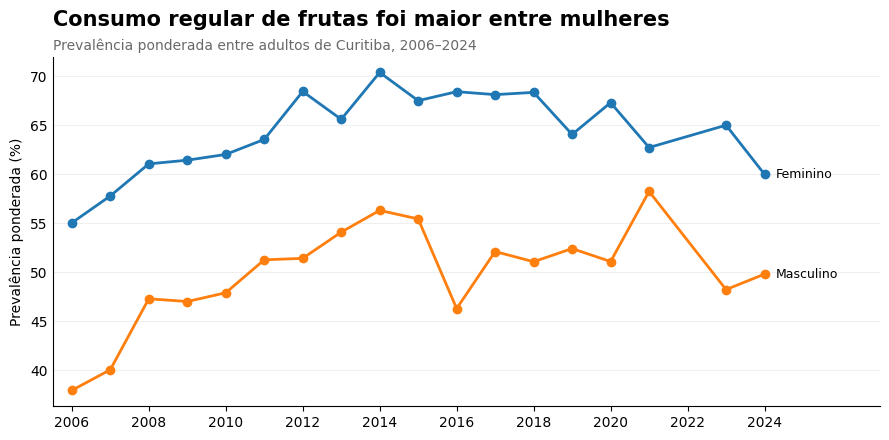

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))

for sexo in frutas_sexo['Sexo'].unique():

    dados_plot = frutas_sexo[
        frutas_sexo['Sexo'] == sexo
    ]

    ax.plot(
        dados_plot['Ano'],
        dados_plot['Prevalência (%)'],
        marker='o',
        linewidth=2
    )

    # Identificar cada linha diretamente
    ax.text(
        dados_plot['Ano'].iloc[-1] + 0.3,
        dados_plot['Prevalência (%)'].iloc[-1],
        sexo,
        va='center',
        fontsize=9
    )

ax.set_title(
    'Consumo regular de frutas foi maior entre mulheres',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2006–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('')

ax.set_xticks(range(2006, 2025, 2))
ax.set_xlim(2005.5, 2027)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

### Consumo regular de frutas segundo sexo

Ao longo de todo o período analisado, o consumo regular de frutas foi mais frequente entre mulheres do que entre homens. Embora a prevalência varie ao longo dos anos nos dois grupos, a diferença entre os sexos permanece durante toda a série.

Essa análise é descritiva e não considera possíveis diferenças de idade ou escolaridade entre homens e mulheres. Posteriormente, serão utilizados modelos de regressão logística para verificar se essa associação permanece quando essas características são consideradas simultaneamente.

In [ ]:
import statsmodels.formula.api as smf

# Centralizar o ano para facilitar a interpretação
frutas_sexo_modelo = frutas_sexo.copy()

frutas_sexo_modelo['Ano_c'] = (
    frutas_sexo_modelo['Ano']
    - frutas_sexo_modelo['Ano'].min()
)

# Regressão com interação entre ano e sexo
modelo_frutas_sexo = smf.ols(
    'Q("Prevalência (%)") ~ Ano_c * C(Sexo)',
    data=frutas_sexo_modelo
).fit()

print(modelo_frutas_sexo.summary())

                             OLS Regression Results                             
Dep. Variable:     Q("Prevalência (%)")   R-squared:                       0.784
Model:                              OLS   Adj. R-squared:                  0.764
Method:                   Least Squares   F-statistic:                     38.69
Date:                  Tue, 13 Oct 2026   Prob (F-statistic):           9.33e-11
Time:                          17:36:35   Log-Likelihood:                -100.65
No. Observations:                    36   AIC:                             209.3
Df Residuals:                        32   BIC:                             215.6
Df Model:                             3                                         
Covariance Type:              nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------


### Tendência temporal segundo sexo

O consumo regular de frutas permaneceu mais frequente entre mulheres ao longo da série. No início do período, a prevalência estimada entre os homens foi aproximadamente 16,0 pontos percentuais menor (β = -16,05; p < 0,001).

Entretanto, a interação entre ano e sexo não foi estatisticamente significativa (β = 0,19; p = 0,467). Portanto, embora homens e mulheres apresentem níveis diferentes de consumo regular de frutas, não há evidência de que a evolução temporal desse indicador tenha ocorrido de maneira diferente entre os sexos.

### Indicadores selecionados para a análise sociodemográfica

Para a análise segundo sexo, faixa etária e escolaridade, foram selecionados indicadores que representam diferentes dimensões dos hábitos alimentares:

- consumo regular de frutas (`frutareg`);
- consumo regular de feijão (`feijao5`);
- consumo regular de refrigerantes (`refritl5`);
- consumo recomendado de frutas e hortaliças (`flvreco`);
- consumo de cinco ou mais grupos de alimentos ultraprocessados (`score_upp_2cat`).

A seleção reduz a redundância entre indicadores semelhantes e permite comparar marcadores de alimentação tradicional, consumo de frutas e hortaliças e consumo de alimentos ultraprocessados. Cada indicador é analisado apenas no período em que sua definição e disponibilidade permitem comparação.

In [ ]:
# Função para calcular prevalência ponderada por ano e grupo

def prevalencia_por_grupo(dados, indicador, grupo):

    resultados = []

    for (ano, categoria), df_grupo in dados.groupby(['ano', grupo]):

        validos = df_grupo[
            [indicador, 'pesorake2025']
        ].dropna()

        if len(validos) > 0:

            prevalencia = (
                (
                    validos[indicador]
                    * validos['pesorake2025']
                ).sum()
                / validos['pesorake2025'].sum()
            ) * 100

            resultados.append({
                'Ano': ano,
                grupo: categoria,
                'Prevalência (%)': prevalencia
            })

    return pd.DataFrame(resultados)

In [ ]:
# Calcular os demais indicadores selecionados por sexo

indicadores_sexo = {
    'feijao5': 'Consumo regular de feijão',
    'refritl5': 'Consumo regular de refrigerantes',
    'flvreco': 'Consumo recomendado de frutas e hortaliças',
    'score_upp_2cat': '5+ grupos de alimentos ultraprocessados'
}

resultados_indicadores_sexo = {}

for indicador, nome in indicadores_sexo.items():

    resultado = prevalencia_por_grupo(
        curitiba,
        indicador,
        'Sexo'
    )

    resultados_indicadores_sexo[indicador] = resultado

    print('=' * 80)
    print(nome)

    tabela = (
        resultado
        .pivot(
            index='Ano',
            columns='Sexo',
            values='Prevalência (%)'
        )
        .round(1)
    )

    display(tabela)

Consumo regular de feijão


Sexo,Feminino,Masculino
Ano,,
2007,52.5,68.4
2008,54.3,71.5
2009,55.1,71.4
2010,56.3,71.1
2011,57.3,73.0
2012,55.3,72.2
2013,57.0,72.7
2014,54.1,69.2
2015,58.7,70.9


Consumo regular de refrigerantes


Sexo,Feminino,Masculino
Ano,,
2007,33.4,45.0
2008,27.8,36.0
2009,26.1,36.5
2010,29.1,36.5
2011,26.5,37.7
2012,26.0,36.0
2013,24.7,29.0
2014,21.4,30.1
2015,19.1,23.6


Consumo recomendado de frutas e hortaliças


Sexo,Feminino,Masculino
Ano,,
2008,27.7,15.8
2009,29.8,17.6
2010,26.7,16.5
2011,28.1,20.1
2012,33.4,20.2
2013,31.8,20.8
2014,34.5,24.8
2015,33.3,25.5
2016,33.3,24.3


5+ grupos de alimentos ultraprocessados


Sexo,Feminino,Masculino
Ano,,
2018,16.6,26.2
2019,17.5,26.0
2020,20.0,26.5
2021,18.3,33.5
2023,18.7,26.8


### Padrões alimentares segundo sexo

A análise segundo sexo compara a prevalência dos indicadores alimentares selecionados entre homens e mulheres ao longo do período disponível para cada indicador.

Primeiro, as séries são apresentadas graficamente para identificar diferenças nos níveis de consumo. Em seguida, para os indicadores com séries temporais mais longas, são utilizados modelos com interação entre ano e sexo para verificar se a evolução temporal difere entre os grupos.

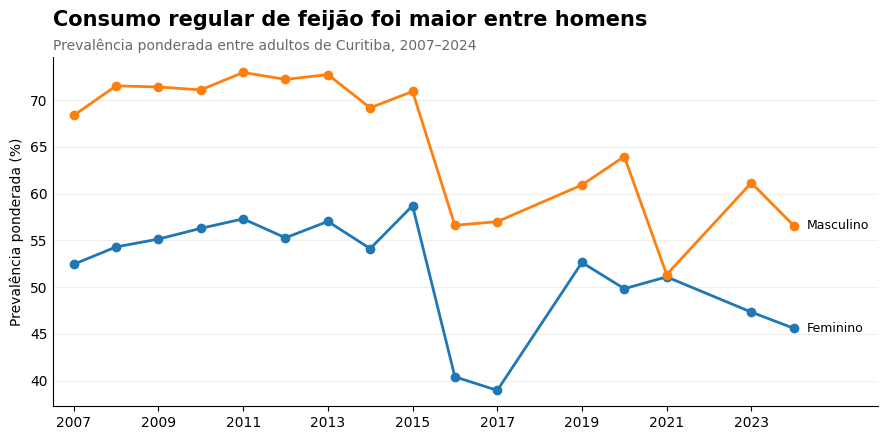

In [ ]:
resultado = resultados_indicadores_sexo['feijao5']

fig, ax = plt.subplots(figsize=(9, 4.5))

for sexo in ['Feminino', 'Masculino']:

    dados_plot = resultado[
        resultado['Sexo'] == sexo
    ]

    ax.plot(
        dados_plot['Ano'],
        dados_plot['Prevalência (%)'],
        marker='o',
        linewidth=2
    )

    ax.text(
        dados_plot['Ano'].iloc[-1] + 0.3,
        dados_plot['Prevalência (%)'].iloc[-1],
        sexo,
        va='center',
        fontsize=9
    )

ax.set_title(
    'Consumo regular de feijão foi maior entre homens',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2007–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('')

# Eixo X uniforme
ax.set_xticks([2007, 2009, 2011, 2013, 2015, 2017, 2019, 2021, 2023])
ax.set_xlim(2006.5, 2026)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

Ao longo de praticamente toda a série, o consumo regular de feijão foi mais frequente entre homens. A queda acentuada observada a partir de 2016 ocorreu em ambos os grupos, indicando que a ruptura não esteve restrita a um único sexo.

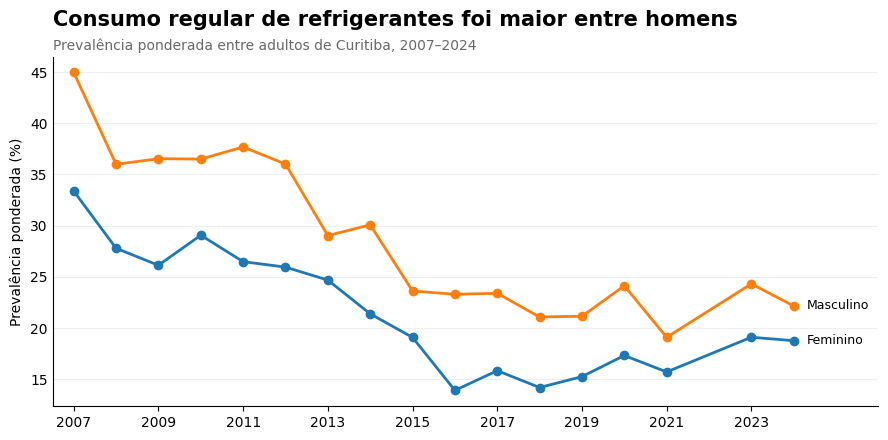

In [ ]:
resultado = resultados_indicadores_sexo['refritl5']

fig, ax = plt.subplots(figsize=(9, 4.5))

for sexo in ['Feminino', 'Masculino']:

    dados_plot = resultado[
        resultado['Sexo'] == sexo
    ]

    ax.plot(
        dados_plot['Ano'],
        dados_plot['Prevalência (%)'],
        marker='o',
        linewidth=2
    )

    ax.text(
        dados_plot['Ano'].iloc[-1] + 0.3,
        dados_plot['Prevalência (%)'].iloc[-1],
        sexo,
        va='center',
        fontsize=9
    )

ax.set_title(
    'Consumo regular de refrigerantes foi maior entre homens',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2007–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('')

ax.set_xticks([2007, 2009, 2011, 2013, 2015, 2017, 2019, 2021, 2023])
ax.set_xlim(2006.5, 2026)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

O consumo regular de refrigerantes foi mais frequente entre homens durante todo o período analisado. Apesar dessa diferença entre os grupos, observa-se uma redução do consumo ao longo do tempo tanto entre homens quanto entre mulheres.

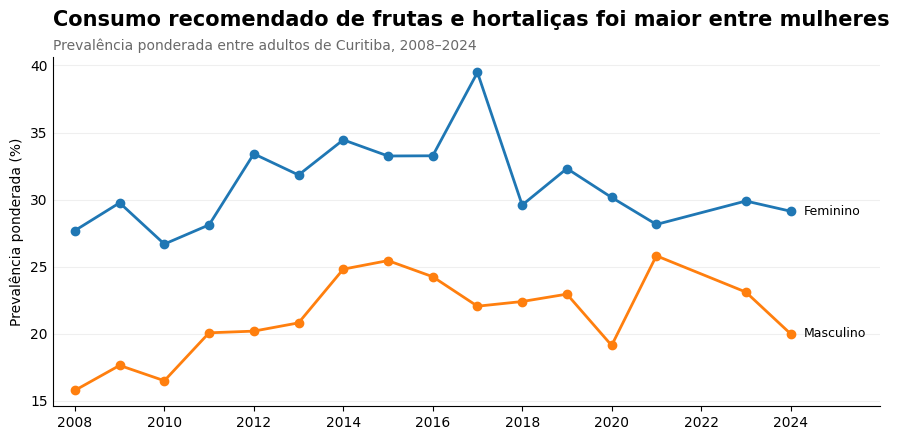

In [ ]:
resultado = resultados_indicadores_sexo['flvreco']

fig, ax = plt.subplots(figsize=(9, 4.5))

for sexo in ['Feminino', 'Masculino']:

    dados_plot = resultado[
        resultado['Sexo'] == sexo
    ]

    ax.plot(
        dados_plot['Ano'],
        dados_plot['Prevalência (%)'],
        marker='o',
        linewidth=2
    )

    ax.text(
        dados_plot['Ano'].iloc[-1] + 0.3,
        dados_plot['Prevalência (%)'].iloc[-1],
        sexo,
        va='center',
        fontsize=9
    )

ax.set_title(
    'Consumo recomendado de frutas e hortaliças foi maior entre mulheres',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2008–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('')

ax.set_xticks([2008, 2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024])
ax.set_xlim(2007.5, 2026)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

O consumo recomendado de frutas e hortaliças foi mais frequente entre mulheres durante todo o período analisado. Embora os valores oscilem ao longo dos anos, a diferença entre homens e mulheres permanece visível durante toda a série.

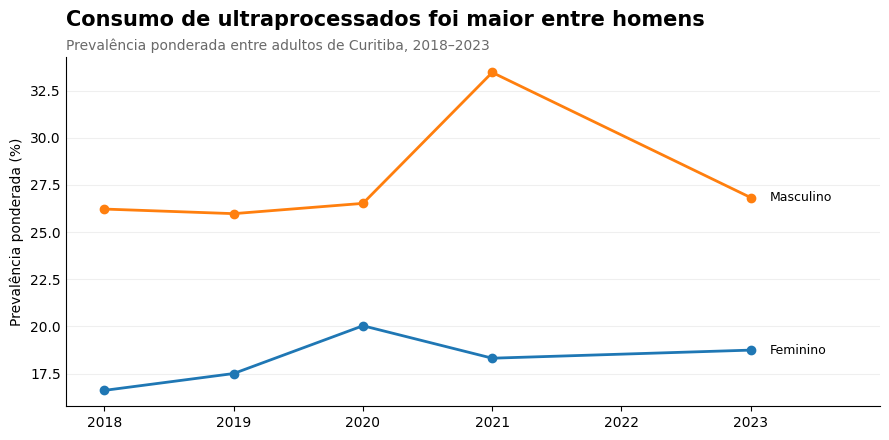

In [ ]:
resultado = resultados_indicadores_sexo['score_upp_2cat']

fig, ax = plt.subplots(figsize=(9, 4.5))

for sexo in ['Feminino', 'Masculino']:

    dados_plot = resultado[
        resultado['Sexo'] == sexo
    ]

    ax.plot(
        dados_plot['Ano'],
        dados_plot['Prevalência (%)'],
        marker='o',
        linewidth=2
    )

    ax.text(
        dados_plot['Ano'].iloc[-1] + 0.15,
        dados_plot['Prevalência (%)'].iloc[-1],
        sexo,
        va='center',
        fontsize=9
    )

ax.set_title(
    'Consumo de ultraprocessados foi maior entre homens',
    loc='left',
    fontsize=15,
    fontweight='bold',
    pad=22
)

ax.text(
    0,
    1.02,
    'Prevalência ponderada entre adultos de Curitiba, 2018–2023',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray'
)

ax.set_ylabel('Prevalência ponderada (%)')
ax.set_xlabel('')

ax.set_xticks([2018, 2019, 2020, 2021, 2022, 2023])
ax.set_xlim(2017.7, 2024)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

O consumo de cinco ou mais grupos de alimentos ultraprocessados foi mais frequente entre homens em todos os anos disponíveis. A diferença entre os sexos foi particularmente acentuada em 2021, mas a série curta recomenda cautela na interpretação de tendências temporais.

In [ ]:
# Regressões com interação entre ano e sexo
# para os indicadores com séries temporais mais longas

indicadores_interacao_sexo = {
    'feijao5': 'Consumo regular de feijão',
    'refritl5': 'Consumo regular de refrigerantes',
    'flvreco': 'Consumo recomendado de frutas e hortaliças'
}

resultados_interacao_sexo = []

for indicador, nome in indicadores_interacao_sexo.items():

    df_modelo = resultados_indicadores_sexo[indicador].copy()

    # Centralizar o ano no primeiro ano disponível de cada indicador
    df_modelo['Ano_c'] = (
        df_modelo['Ano'] - df_modelo['Ano'].min()
    )

    modelo = smf.ols(
        'Q("Prevalência (%)") ~ Ano_c * C(Sexo)',
        data=df_modelo
    ).fit()

    # Extrair especificamente o coeficiente da interação
    termo_interacao = 'Ano_c:C(Sexo)[T.Masculino]'

    resultados_interacao_sexo.append({
        'Indicador': nome,
        'β interação (p.p./ano)': modelo.params[termo_interacao],
        'p-valor interação': modelo.pvalues[termo_interacao],
        'R²': modelo.rsquared
    })

tabela_interacao_sexo = pd.DataFrame(
    resultados_interacao_sexo
)

display(
    tabela_interacao_sexo.round(4)
)

,Indicador,β interação (p.p./ano),p-valor interação,R²
0,Consumo regular de feijão,-0.4606,0.1830,0.7574
1,Consumo regular de refrigerantes,-0.3670,0.1434,0.8005
2,Consumo recomendado de frutas e hortaliças,0.2694,0.2366,0.7581


### Síntese da análise segundo sexo

A análise revelou diferenças persistentes nos padrões alimentares de homens e mulheres em Curitiba. Ao longo dos anos observados, as mulheres apresentaram maior prevalência de consumo regular de frutas e de consumo recomendado de frutas e hortaliças. Em sentido contrário, os homens apresentaram maior prevalência de consumo regular de feijão e refrigerantes. Entre 2018 e 2023, o consumo de cinco ou mais grupos de alimentos ultraprocessados também foi maior entre os homens em todos os anos observados.

Apesar dessas diferenças nos níveis de consumo, os modelos de interação entre ano e sexo não encontraram evidências de que as tendências temporais tenham sido diferentes entre homens e mulheres. As interações não foram estatisticamente significativas para consumo regular de frutas (p = 0,467), feijão (p = 0,183), refrigerantes (p = 0,143) ou consumo recomendado de frutas e hortaliças (p = 0,237).

Assim, os resultados indicam diferenças entre homens e mulheres nos níveis de alguns comportamentos alimentares, mas não mostram que essas diferenças tenham aumentado ou diminuído de maneira sistematicamente distinta ao longo do período analisado.

In [ ]:
# Calcular os indicadores selecionados por faixa etária

indicadores_idade = {
    'frutareg': 'Consumo regular de frutas',
    'feijao5': 'Consumo regular de feijão',
    'refritl5': 'Consumo regular de refrigerantes',
    'flvreco': 'Consumo recomendado de frutas e hortaliças',
    'score_upp_2cat': '5+ grupos de alimentos ultraprocessados'
}

resultados_indicadores_idade = {}

ordem_idade = [
    '18–24 anos',
    '25–34 anos',
    '35–44 anos',
    '45–54 anos',
    '55–64 anos',
    '65 anos ou mais'
]

for indicador, nome in indicadores_idade.items():

    resultado = prevalencia_por_grupo(
        curitiba,
        indicador,
        'Faixa etária'
    )

    resultados_indicadores_idade[indicador] = resultado

    tabela = (
        resultado
        .pivot(
            index='Ano',
            columns='Faixa etária',
            values='Prevalência (%)'
        )
        .reindex(columns=ordem_idade)
        .round(1)
    )

    print('=' * 100)
    print(nome)

    display(tabela)

Consumo regular de frutas


Faixa etária,18–24 anos,25–34 anos,35–44 anos,45–54 anos,55–64 anos,65 anos ou mais
Ano,,,,,,
2006,32.5,40.5,44.6,57.1,60.6,65.0
2007,38.9,38.6,45.2,62.3,63.4,68.6
2008,44.1,46.0,54.4,59.9,65.4,74.1
2009,49.1,44.6,49.5,59.2,68.0,77.1
2010,45.1,46.8,48.9,64.0,69.2,75.5
2011,50.0,49.2,54.7,58.9,69.7,80.3
2012,62.2,53.3,53.7,58.8,70.1,78.5
2013,50.7,56.1,53.7,64.7,67.3,78.2
2014,64.4,50.7,59.3,69.2,70.5,80.6


Consumo regular de feijão


Faixa etária,18–24 anos,25–34 anos,35–44 anos,45–54 anos,55–64 anos,65 anos ou mais
Ano,,,,,,
2007,63.2,62.7,60.8,59.6,54.1,51.3
2008,61.7,59.7,66.7,61.9,63.6,60.0
2009,59.3,65.5,62.9,63.0,63.2,60.5
2010,69.1,61.9,67.7,61.0,59.1,56.5
2011,71.5,65.1,62.7,66.5,62.0,56.1
2012,68.0,63.4,62.2,62.1,59.0,64.0
2013,70.2,68.0,65.7,62.5,56.8,57.8
2014,66.7,60.5,61.8,59.3,63.4,54.4
2015,64.9,64.8,66.9,67.8,61.0,57.5


Consumo regular de refrigerantes


Faixa etária,18–24 anos,25–34 anos,35–44 anos,45–54 anos,55–64 anos,65 anos ou mais
Ano,,,,,,
2007,53.0,48.0,35.9,31.9,25.2,22.3
2008,38.4,44.3,30.2,25.5,19.7,14.5
2009,36.9,40.0,33.5,26.7,17.7,16.0
2010,38.7,41.3,35.5,30.3,14.8,19.7
2011,48.8,36.8,29.9,30.4,19.9,13.0
2012,36.9,37.2,32.9,28.5,22.7,15.7
2013,39.7,30.0,30.3,20.4,20.3,13.3
2014,39.7,31.9,25.1,20.1,15.3,15.0
2015,29.8,24.1,25.4,16.9,12.7,13.8


Consumo recomendado de frutas e hortaliças


Faixa etária,18–24 anos,25–34 anos,35–44 anos,45–54 anos,55–64 anos,65 anos ou mais
Ano,,,,,,
2008,12.4,21.1,21.2,27.6,31.2,24.0
2009,18.9,18.1,22.4,29.0,32.9,33.0
2010,13.0,16.8,21.7,28.4,26.9,32.3
2011,19.3,24.9,19.6,22.8,31.4,35.0
2012,26.8,26.0,25.0,25.8,30.4,33.7
2013,20.3,24.8,24.3,33.5,29.7,29.5
2014,30.5,20.9,30.9,37.1,33.4,30.8
2015,29.9,23.1,31.2,30.1,35.0,32.1
2016,17.1,28.5,29.4,30.6,35.0,34.0


5+ grupos de alimentos ultraprocessados


Faixa etária,18–24 anos,25–34 anos,35–44 anos,45–54 anos,55–64 anos,65 anos ou mais
Ano,,,,,,
2018,29.1,29.6,20.4,22.3,10.8,10.5
2019,35.6,27.1,19.6,21.3,13.2,11.7
2020,45.3,30.6,21.1,18.1,12.9,12.6
2021,32.3,27.7,30.2,28.0,14.6,17.4
2023,35.9,36.5,22.4,18.2,11.8,11.6


### Consumo alimentar segundo faixa etária

Para investigar como os hábitos alimentares variam entre os grupos de idade, as prevalências ponderadas dos indicadores selecionados foram calculadas para seis faixas etárias.

Os resultados são apresentados em mapas de calor (heatmaps), que permitem comparar simultaneamente as diferenças entre as faixas etárias e as mudanças ao longo dos anos.

### Tamanho das subamostras por faixa etária

O número de participantes varia entre as faixas etárias e ao longo dos anos. As menores subamostras foram observadas entre os adultos mais jovens, chegando a 47 participantes na faixa de 18–24 anos e 66 na faixa de 25–34 anos.

Por isso, oscilações anuais isoladas nesses grupos devem ser interpretadas com cautela, priorizando-se padrões persistentes ao longo do período.

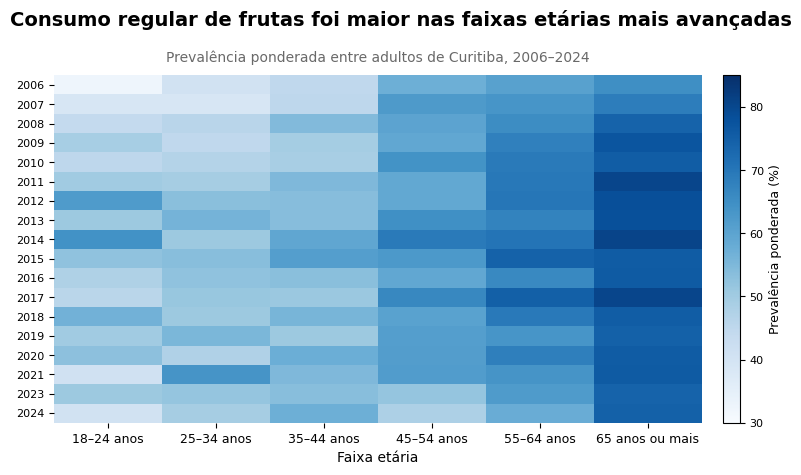

In [ ]:
## Heatmap — consumo regular de frutas por faixa etária

import matplotlib.pyplot as plt
import numpy as np

resultado = resultados_indicadores_idade['frutareg']

tabela_heatmap = (
    resultado
    .pivot(
        index='Ano',
        columns='Faixa etária',
        values='Prevalência (%)'
    )
    .reindex(columns=ordem_idade)
)

# Criar gráfico
fig, ax = plt.subplots(figsize=(8, 4.8))

# Heatmap
imagem = ax.imshow(
    tabela_heatmap.values,
    aspect='auto',
    cmap='Blues',
    vmin=30,
    vmax=85
)

# Eixo X
ax.set_xticks(np.arange(len(tabela_heatmap.columns)))
ax.set_xticklabels(
    tabela_heatmap.columns,
    rotation=0,
    fontsize=9
)

# Eixo Y
ax.set_yticks(np.arange(len(tabela_heatmap.index)))
ax.set_yticklabels(
    tabela_heatmap.index,
    fontsize=8
)

# Remover bordas desnecessárias
for spine in ax.spines.values():
    spine.set_visible(False)

# Título principal
fig.suptitle(
    'Consumo regular de frutas foi maior nas faixas etárias mais avançadas',
    fontsize=14,
    fontweight='bold',
    y=0.98
)

# Subtítulo
ax.set_title(
    'Prevalência ponderada entre adultos de Curitiba, 2006–2024',
    fontsize=10,
    color='dimgray',
    pad=10
)

# Eixos
ax.set_xlabel('Faixa etária', fontsize=10)
ax.set_ylabel('')

# Barra de cores
barra = fig.colorbar(
    imagem,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

barra.set_label(
    'Prevalência ponderada (%)',
    fontsize=9
)

barra.ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

**Leitura descritiva:** O consumo regular de frutas apresenta um claro gradiente etário. De modo geral, as prevalências são maiores nas faixas etárias mais elevadas, especialmente entre pessoas com 65 anos ou mais, enquanto os grupos mais jovens apresentam valores menores e maior oscilação ao longo da série.

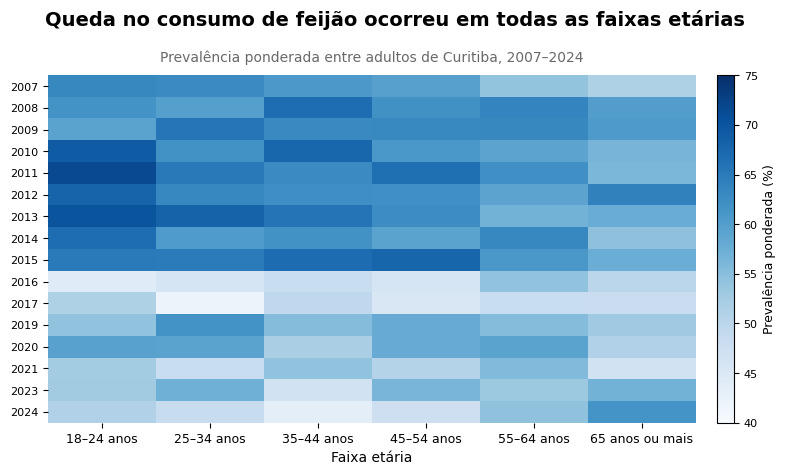

In [ ]:
# Heatmap — consumo regular de feijão por faixa etária

import matplotlib.pyplot as plt
import numpy as np

resultado = resultados_indicadores_idade['feijao5']

tabela_heatmap = (
    resultado
    .pivot(
        index='Ano',
        columns='Faixa etária',
        values='Prevalência (%)'
    )
    .reindex(columns=ordem_idade)
)

# Criar gráfico
fig, ax = plt.subplots(figsize=(8, 4.8))

# Heatmap
imagem = ax.imshow(
    tabela_heatmap.values,
    aspect='auto',
    cmap='Blues',
    vmin=40,
    vmax=75
)

# Eixo X
ax.set_xticks(np.arange(len(tabela_heatmap.columns)))
ax.set_xticklabels(
    tabela_heatmap.columns,
    rotation=0,
    fontsize=9
)

# Eixo Y
ax.set_yticks(np.arange(len(tabela_heatmap.index)))
ax.set_yticklabels(
    tabela_heatmap.index,
    fontsize=8
)

# Remover bordas desnecessárias
for spine in ax.spines.values():
    spine.set_visible(False)

# Título principal
fig.suptitle(
    'Queda no consumo de feijão ocorreu em todas as faixas etárias',
    fontsize=14,
    fontweight='bold',
    y=0.98
)

# Subtítulo
ax.set_title(
    'Prevalência ponderada entre adultos de Curitiba, 2007–2024',
    fontsize=10,
    color='dimgray',
    pad=10
)

# Eixos
ax.set_xlabel('Faixa etária', fontsize=10)
ax.set_ylabel('')

# Barra de cores
barra = fig.colorbar(
    imagem,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

barra.set_label(
    'Prevalência ponderada (%)',
    fontsize=9
)

barra.ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

**Leitura descritiva:** Diferentemente do consumo de frutas, o consumo regular de feijão não apresenta um gradiente etário consistente ao longo da série. Observa-se uma redução acentuada entre 2015 e 2016 em praticamente todas as faixas etárias, seguida por oscilações nos anos posteriores. A ocorrência da queda em diferentes grupos etários indica que a ruptura observada na série geral não está concentrada em uma faixa etária específica.

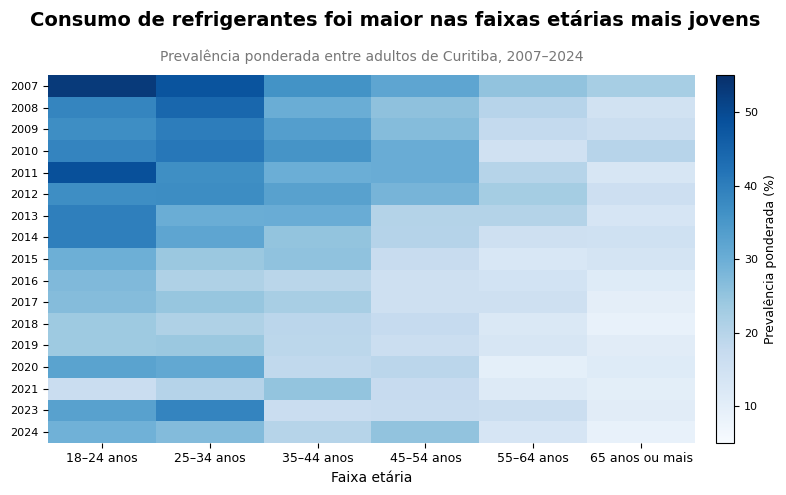

In [ ]:
# Heatmap — consumo regular de refrigerantes por faixa etária

import matplotlib.pyplot as plt
import numpy as np

resultado = resultados_indicadores_idade['refritl5']

tabela_heatmap = (
    resultado
    .pivot(
        index='Ano',
        columns='Faixa etária',
        values='Prevalência (%)'
    )
    .reindex(columns=ordem_idade)
)

fig, ax = plt.subplots(figsize=(8, 5))

imagem = ax.imshow(
    tabela_heatmap.values,
    aspect='auto',
    cmap='Blues',
    vmin=5,
    vmax=55
)

# Eixo X
ax.set_xticks(np.arange(len(tabela_heatmap.columns)))
ax.set_xticklabels(
    tabela_heatmap.columns,
    fontsize=9
)

# Eixo Y
ax.set_yticks(np.arange(len(tabela_heatmap.index)))
ax.set_yticklabels(
    tabela_heatmap.index,
    fontsize=8
)

# Remover bordas desnecessárias
for spine in ax.spines.values():
    spine.set_visible(False)

# Título e subtítulo
fig.suptitle(
    'Consumo de refrigerantes foi maior nas faixas etárias mais jovens',
    fontsize=14,
    fontweight='bold',
    y=0.98
)

ax.set_title(
    'Prevalência ponderada entre adultos de Curitiba, 2007–2024',
    fontsize=10,
    color='#777777',
    pad=10
)

ax.set_xlabel(
    'Faixa etária',
    fontsize=10
)

ax.set_ylabel('')

# Barra de cores
barra = fig.colorbar(
    imagem,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

barra.set_label(
    'Prevalência ponderada (%)',
    fontsize=9
)

barra.ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

**Leitura descritiva:** O consumo regular de refrigerantes apresenta um gradiente etário consistente, com prevalências geralmente mais elevadas entre os adultos mais jovens e menores entre os grupos de maior idade. Também se observa redução do consumo ao longo da série em praticamente todas as faixas etárias, apesar de algumas oscilações anuais.

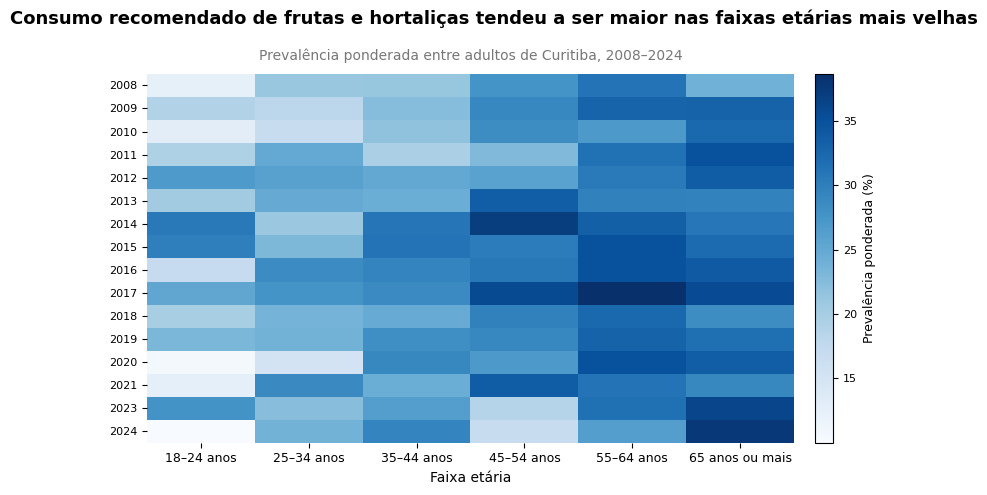

In [ ]:
# Heatmap — consumo recomendado de frutas e hortaliças por faixa etária

import matplotlib.pyplot as plt
import numpy as np

resultado = resultados_indicadores_idade['flvreco']

tabela_heatmap = (
    resultado
    .pivot(
        index='Ano',
        columns='Faixa etária',
        values='Prevalência (%)'
    )
    .reindex(columns=ordem_idade)
)

fig, ax = plt.subplots(figsize=(8, 5))

imagem = ax.imshow(
    tabela_heatmap.values,
    aspect='auto',
    cmap='Blues'
)

# Eixo X
ax.set_xticks(np.arange(len(tabela_heatmap.columns)))
ax.set_xticklabels(
    tabela_heatmap.columns,
    fontsize=9
)

# Eixo Y
ax.set_yticks(np.arange(len(tabela_heatmap.index)))
ax.set_yticklabels(
    tabela_heatmap.index,
    fontsize=8
)

# Remover bordas desnecessárias
for spine in ax.spines.values():
    spine.set_visible(False)

# Título e subtítulo
fig.suptitle(
    'Consumo recomendado de frutas e hortaliças tendeu a ser maior nas faixas etárias mais velhas',
    fontsize=13,
    fontweight='bold',
    y=0.98
)

ax.set_title(
    'Prevalência ponderada entre adultos de Curitiba, 2008–2024',
    fontsize=10,
    color='#777777',
    pad=10
)

# Eixos
ax.set_xlabel(
    'Faixa etária',
    fontsize=10
)

ax.set_ylabel('')

# Barra de cores
barra = fig.colorbar(
    imagem,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

barra.set_label(
    'Prevalência ponderada (%)',
    fontsize=9
)

barra.ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

**Leitura descritiva:** O consumo recomendado de frutas e hortaliças apresenta diferenças segundo a faixa etária, com prevalências geralmente mais elevadas entre os grupos de maior idade, especialmente entre adultos de 55–64 anos e de 65 anos ou mais. Entretanto, o gradiente etário é menos regular do que o observado para o consumo de frutas isoladamente, com oscilações entre as faixas intermediárias ao longo da série.

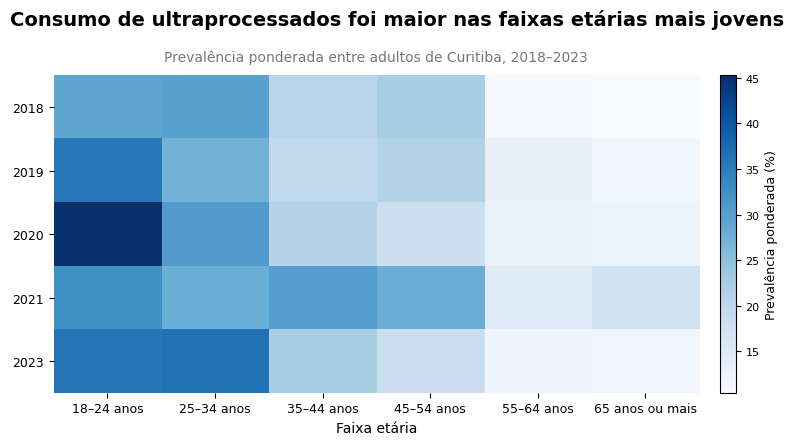

In [ ]:
# Heatmap — consumo de ultraprocessados por faixa etária

import matplotlib.pyplot as plt
import numpy as np

resultado = resultados_indicadores_idade['score_upp_2cat']

tabela_heatmap = (
    resultado
    .pivot(
        index='Ano',
        columns='Faixa etária',
        values='Prevalência (%)'
    )
    .reindex(columns=ordem_idade)
)

fig, ax = plt.subplots(figsize=(8, 4.5))

imagem = ax.imshow(
    tabela_heatmap.values,
    aspect='auto',
    cmap='Blues'
)

# Eixo X
ax.set_xticks(np.arange(len(tabela_heatmap.columns)))
ax.set_xticklabels(
    tabela_heatmap.columns,
    fontsize=9
)

# Eixo Y
ax.set_yticks(np.arange(len(tabela_heatmap.index)))
ax.set_yticklabels(
    tabela_heatmap.index,
    fontsize=9
)

# Remover bordas desnecessárias
for spine in ax.spines.values():
    spine.set_visible(False)

# Título e subtítulo
fig.suptitle(
    'Consumo de ultraprocessados foi maior nas faixas etárias mais jovens',
    fontsize=14,
    fontweight='bold',
    y=0.98
)

ax.set_title(
    'Prevalência ponderada entre adultos de Curitiba, 2018–2023',
    fontsize=10,
    color='#777777',
    pad=10
)

# Eixos
ax.set_xlabel(
    'Faixa etária',
    fontsize=10
)

ax.set_ylabel('')

# Barra de cores
barra = fig.colorbar(
    imagem,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

barra.set_label(
    'Prevalência ponderada (%)',
    fontsize=9
)

barra.ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

**Leitura descritiva:** O consumo de cinco ou mais grupos de alimentos ultraprocessados apresenta um gradiente etário evidente. As maiores prevalências são observadas entre os adultos mais jovens, enquanto os grupos de 55–64 anos e de 65 anos ou mais apresentam os menores valores. Apesar das oscilações anuais, esse padrão se mantém ao longo do período analisado. Como o indicador está disponível para apenas cinco anos (2018–2023), ele será mantido como evidência descritiva, sem análise de tendência temporal por faixa etária.

### Síntese descritiva segundo faixa etária

A análise evidencia que **não existe um único padrão de associação entre faixa etária e consumo alimentar**. O padrão observado varia conforme o indicador analisado.

- **Consumo regular de frutas:** observa-se um gradiente etário positivo, com prevalências geralmente mais elevadas nas faixas de maior idade.
- **Consumo regular de feijão:** não apresenta um gradiente etário consistente. Destaca-se, entretanto, a redução acentuada entre 2015 e 2016, observada em praticamente todas as faixas etárias.
- **Consumo regular de refrigerantes:** apresenta um gradiente etário inverso, com prevalências geralmente mais elevadas entre os adultos mais jovens e menores entre os grupos de maior idade.
- **Consumo recomendado de frutas e hortaliças:** as prevalências tendem a ser maiores nas faixas etárias mais elevadas, embora o gradiente seja menos regular e apresente maior oscilação ao longo do período.
- **Consumo de cinco ou mais grupos de alimentos ultraprocessados:** apresenta um forte gradiente etário inverso, com maiores prevalências entre os adultos mais jovens e menores prevalências entre os grupos de maior idade.

Em conjunto, os resultados descritivos sugerem **padrões alimentares distintos associados às diferentes faixas etárias**, em vez de uma relação única entre idade e alimentação. A análise estatística seguinte permitirá avaliar se as diferenças observadas entre os grupos e suas trajetórias temporais apresentam evidência estatística nos modelos utilizados.

A interpretação dos mecanismos sociais associados a esses padrões — incluindo possíveis diferenças geracionais, características do ciclo de vida e transformações do sistema alimentar — será desenvolvida posteriormente, na etapa de contextualização e discussão dos resultados.

### Há evidência de que as trajetórias temporais diferem entre as faixas etárias?

A análise descritiva mostrou diferenças importantes entre os grupos de idade. O próximo passo é verificar se, além dessas diferenças nos níveis de consumo, **as mudanças ao longo do tempo também ocorreram de maneira diferente entre as faixas etárias**.

Para isso, serão utilizados modelos com interação entre ano e faixa etária. O teste conjunto da interação permite avaliar se as trajetórias temporais diferem significativamente entre os grupos.

In [ ]:
# Análise estatística por faixa etária
# Teste conjunto da interação Ano × Faixa etária

import statsmodels.formula.api as smf
import statsmodels.api as sm

indicadores_interacao_idade = {
    'frutareg': 'Consumo regular de frutas',
    'feijao5': 'Consumo regular de feijão',
    'refritl5': 'Consumo regular de refrigerantes',
    'flvreco': 'Consumo recomendado de frutas e hortaliças'
}

resultados_interacao_idade = []

for indicador, nome in indicadores_interacao_idade.items():

    df_modelo = resultados_indicadores_idade[indicador].copy()

    # Centralizar o ano no primeiro ano disponível
    df_modelo['Ano_c'] = (
        df_modelo['Ano'] - df_modelo['Ano'].min()
    )

    # Modelo sem interação:
    # mesma tendência temporal para todas as faixas etárias
    modelo_sem_interacao = smf.ols(
        'Q("Prevalência (%)") ~ Ano_c + C(Q("Faixa etária"))',
        data=df_modelo
    ).fit()

    # Modelo com interação:
    # permite que a tendência temporal varie por faixa etária
    modelo_com_interacao = smf.ols(
        'Q("Prevalência (%)") ~ Ano_c * C(Q("Faixa etária"))',
        data=df_modelo
    ).fit()

    # Teste F comparando os dois modelos
    teste = sm.stats.anova_lm(
        modelo_sem_interacao,
        modelo_com_interacao
    )

    p_interacao = teste.loc[1, 'Pr(>F)']
    f_interacao = teste.loc[1, 'F']

    resultados_interacao_idade.append({
        'Indicador': nome,
        'F interação': f_interacao,
        'p-valor interação': p_interacao,
        'R² modelo com interação': modelo_com_interacao.rsquared
    })

tabela_interacao_idade = pd.DataFrame(
    resultados_interacao_idade
)

display(
    tabela_interacao_idade.round(4)
)

,Indicador,F interação,p-valor interação,R² modelo com interação
0,Consumo regular de frutas,2.4616,0.0383,0.8058
1,Consumo regular de feijão,1.7570,0.1306,0.4183
2,Consumo regular de refrigerantes,1.8157,0.1177,0.8050
3,Consumo recomendado de frutas e hortaliças,1.2771,0.2815,0.5469


### Diferenças entre níveis de consumo e trajetórias temporais

A análise por faixa etária mostra que é importante distinguir **diferenças nos níveis de consumo** de **diferenças nas trajetórias ao longo do tempo**.

Os heatmaps mostraram diferenças importantes entre as faixas etárias. No consumo de refrigerantes, por exemplo, as prevalências são geralmente maiores entre os adultos mais jovens. Entretanto, o teste de interação entre ano e faixa etária não foi estatisticamente significativo (p = 0,118). Isso indica que, embora os grupos apresentem níveis diferentes de consumo, não há evidência de que a redução dos refrigerantes tenha ocorrido de maneira diferente entre as faixas etárias.

O mesmo ocorreu para o consumo regular de feijão (p = 0,131) e para o consumo recomendado de frutas e hortaliças (p = 0,282).

A exceção foi o **consumo regular de frutas**. Nesse indicador, a interação entre ano e faixa etária foi estatisticamente significativa (p = 0,038), indicando que a evolução do consumo ao longo do período analisado não foi igual entre todos os grupos de idade.

Por esse motivo, o consumo regular de frutas será examinado com maior detalhe a seguir, buscando identificar quais faixas etárias apresentaram crescimento, estabilidade ou redução ao longo do período.

In [ ]:
# Tendência temporal do consumo regular de frutas
# separadamente por faixa etária

from scipy.stats import linregress

resultado_frutas_idade = resultados_indicadores_idade['frutareg']

tendencias_frutas_idade = []

for faixa in ordem_idade:

    df_faixa = (
        resultado_frutas_idade[
            resultado_frutas_idade['Faixa etária'] == faixa
        ]
        .dropna(subset=['Prevalência (%)'])
        .sort_values('Ano')
    )

    regressao = linregress(
        df_faixa['Ano'],
        df_faixa['Prevalência (%)']
    )

    tendencias_frutas_idade.append({
        'Faixa etária': faixa,
        'Nº de anos': len(df_faixa),
        'β (p.p./ano)': regressao.slope,
        'p-valor': regressao.pvalue,
        'R²': regressao.rvalue ** 2
    })

tabela_tendencias_frutas_idade = pd.DataFrame(
    tendencias_frutas_idade
)

display(
    tabela_tendencias_frutas_idade.round(4)
)

,Faixa etária,Nº de anos,β (p.p./ano),p-valor,R²
0,18–24 anos,18,0.2831,0.4313,0.0391
1,25–34 anos,18,0.6535,0.0058,0.3881
2,35–44 anos,18,0.4331,0.0198,0.2952
3,45–54 anos,18,-0.2948,0.1755,0.1116
4,55–64 anos,18,-0.1396,0.4987,0.0291
5,65 anos ou mais,18,0.1971,0.2589,0.0789


### Tendências do consumo regular de frutas por faixa etária

Após a identificação de uma interação significativa entre ano e faixa etária, foram examinadas as tendências temporais separadamente em cada grupo.

Os resultados indicaram tendência significativa de aumento do consumo regular de frutas entre adultos de **25–34 anos (β = +0,654 p.p./ano; p = 0,006)** e **35–44 anos (β = +0,433 p.p./ano; p = 0,020)**. Nas demais faixas etárias, não foram identificadas tendências lineares estatisticamente significativas.

Portanto, o aumento do consumo regular de frutas observado ao longo da série não ocorreu de maneira uniforme entre as faixas etárias. Os resultados indicam crescimento principalmente entre adultos de 25–44 anos, enquanto nos demais grupos não há evidência estatística de aumento ou redução linear ao longo do período.

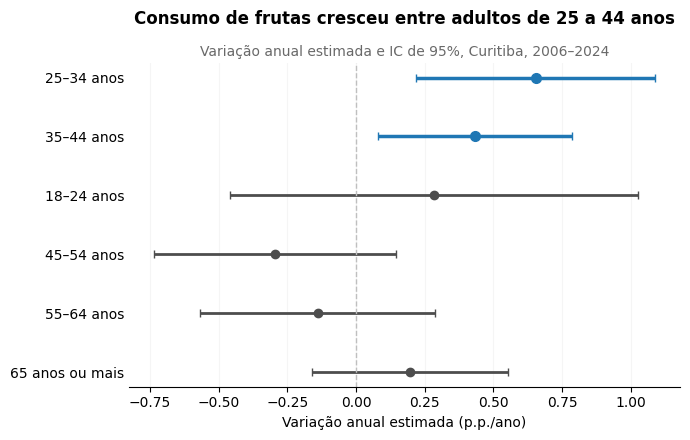

,Faixa etária,β,IC inferior,IC superior
0,18–24 anos,0.283,-0.460,1.027
1,25–34 anos,0.653,0.219,1.088
2,35–44 anos,0.433,0.078,0.788
3,45–54 anos,-0.295,-0.736,0.146
4,55–64 anos,-0.140,-0.567,0.288
5,65 anos ou mais,0.197,-0.160,0.554


In [ ]:
# Coefficient plot das tendências temporais do consumo regular de frutas
# por faixa etária, com intervalo de confiança de 95%

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, t

resultados_coef_frutas = []

for faixa in ordem_idade:

    df_faixa = (
        resultado_frutas_idade[
            resultado_frutas_idade['Faixa etária'] == faixa
        ]
        .dropna(subset=['Prevalência (%)'])
        .sort_values('Ano')
    )

    regressao = linregress(
        df_faixa['Ano'],
        df_faixa['Prevalência (%)']
    )

    # Valor crítico de t para IC de 95%
    gl = len(df_faixa) - 2
    t_critico = t.ppf(0.975, gl)

    margem = t_critico * regressao.stderr

    resultados_coef_frutas.append({
        'Faixa etária': faixa,
        'β': regressao.slope,
        'IC inferior': regressao.slope - margem,
        'IC superior': regressao.slope + margem
    })

coef_frutas = pd.DataFrame(resultados_coef_frutas)

# Organizar as faixas no gráfico
coef_plot = coef_frutas.iloc[::-1].copy()

# Faixas com tendência positiva cujo IC não cruza zero
destaque = coef_plot['Faixa etária'].isin([
    '25–34 anos',
    '35–44 anos'
])

# Criar gráfico
fig, ax = plt.subplots(figsize=(7, 4.5))

# Demais faixas etárias
ax.errorbar(
    coef_plot.loc[~destaque, 'β'],
    coef_plot.loc[~destaque, 'Faixa etária'],
    xerr=[
        coef_plot.loc[~destaque, 'β'] - coef_plot.loc[~destaque, 'IC inferior'],
        coef_plot.loc[~destaque, 'IC superior'] - coef_plot.loc[~destaque, 'β']
    ],
    fmt='o',
    capsize=3,
    color='0.30',
    ecolor='0.30',
    elinewidth=2,
    markersize=6
)

# Faixas etárias em destaque
ax.errorbar(
    coef_plot.loc[destaque, 'β'],
    coef_plot.loc[destaque, 'Faixa etária'],
    xerr=[
        coef_plot.loc[destaque, 'β'] - coef_plot.loc[destaque, 'IC inferior'],
        coef_plot.loc[destaque, 'IC superior'] - coef_plot.loc[destaque, 'β']
    ],
    fmt='o',
    capsize=3,
    color='tab:blue',
    ecolor='tab:blue',
    elinewidth=2.5,
    markersize=7
)

# Linha de referência: ausência de tendência
ax.axvline(
    0,
    color='0.75',
    linestyle='--',
    linewidth=1
)

# Título
ax.set_title(
    'Consumo de frutas cresceu entre adultos de 25 a 44 anos',
    fontsize=12,
    fontweight='bold',
    pad=28
)

# Subtítulo
ax.text(
    0.5,
    1.02,
    'Variação anual estimada e IC de 95%, Curitiba, 2006–2024',
    transform=ax.transAxes,
    fontsize=10,
    color='dimgray',
    ha='center'
)

# Eixos
ax.set_xlabel('Variação anual estimada (p.p./ano)')
ax.set_ylabel('')

# Simplificar o visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.grid(axis='x', alpha=0.12)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

# Tabela dos resultados
display(coef_frutas.round(3))

### Tendências temporais por faixa etária

O *coefficient plot* evidencia diferenças nas trajetórias temporais do consumo regular de frutas entre as faixas etárias. Os pontos representam a variação anual estimada (β) e as barras horizontais representam os intervalos de confiança de 95%.

Foram observadas tendências significativas de aumento entre adultos de **25–34 anos** (`β = +0,653 p.p./ano; IC95%: 0,219 a 1,088`) e **35–44 anos** (`β = +0,433 p.p./ano; IC95%: 0,078 a 0,788`). Nas demais faixas etárias, os intervalos de confiança incluem zero, não indicando tendência linear estatisticamente significativa.

## Análise sociodemográfica por escolaridade

Nesta etapa, são analisadas as diferenças nos indicadores alimentares segundo o nível de escolaridade da população adulta de Curitiba. A variável `fesc` classifica os participantes em três grupos: **0–8 anos**, **9–11 anos** e **12 anos ou mais de estudo**.

A análise busca identificar diferenças nos níveis de consumo entre os grupos de escolaridade e verificar se suas trajetórias temporais apresentam padrões distintos ao longo do período analisado.

In [ ]:
# Número de participantes por escolaridade e ano

ordem_escolaridade = [
    '0–8 anos',
    '9–11 anos',
    '12 anos ou mais'
]

# Contagem por ano e escolaridade
# A coluna 'Escolaridade' já foi criada no DataFrame 'curitiba'
n_escolaridade_ano = (
    curitiba
    .groupby(['ano', 'Escolaridade'], observed=False)
    .size()
    .unstack()
    .reindex(columns=ordem_escolaridade)
)

display(n_escolaridade_ano)

print('\nMenor número de participantes observado em cada grupo:')
display(
    n_escolaridade_ano
    .min()
    .rename('Menor n observado')
    .to_frame()
)

Escolaridade,0–8 anos,9–11 anos,12 anos ou mais
ano,,,
2006,691,716,604
2007,661,724,625
2008,663,735,614
2009,675,724,615
2010,685,730,595
2011,683,734,583
2012,578,592,498
2013,694,640,617
2014,560,465,479



Menor número de participantes observado em cada grupo:


,Menor n observado
Escolaridade,
0–8 anos,162
9–11 anos,272
12 anos ou mais,307


### Tamanho das subamostras por escolaridade

O número de participantes varia entre os níveis de escolaridade e ao longo dos anos. O menor número observado foi de 162 participantes no grupo com 0–8 anos de estudo, enquanto os mínimos dos grupos com 9–11 anos e 12 anos ou mais foram, respectivamente, 272 e 307 participantes.

As subamostras são maiores do que as menores observadas na análise por faixa etária, mas oscilações anuais isoladas ainda devem ser interpretadas com cautela, priorizando-se padrões persistentes ao longo do período.

In [ ]:
# Indicadores selecionados para análise por escolaridade

indicadores_escolaridade = {
    'frutareg': 'Consumo regular de frutas',
    'feijao5': 'Consumo regular de feijão',
    'refritl5': 'Consumo regular de refrigerantes',
    'flvreco': 'Consumo recomendado de frutas e hortaliças',
    'score_upp_2cat': '5+ grupos de alimentos ultraprocessados'
}

resultados_indicadores_escolaridade = {}

for indicador, nome in indicadores_escolaridade.items():

    resultados = []

    for (ano, escolaridade), grupo in curitiba.groupby(
        ['ano', 'Escolaridade'],
        observed=False
    ):

        # Selecionar apenas observações válidas para o indicador
        validos = grupo[
            grupo[indicador].notna() &
            grupo['pesorake2025'].notna()
        ]

        if len(validos) > 0:

            prevalencia = (
                (validos[indicador] * validos['pesorake2025']).sum()
                / validos['pesorake2025'].sum()
                * 100
            )

            resultados.append({
                'Ano': ano,
                'Escolaridade': escolaridade,
                'Prevalência (%)': prevalencia
            })

    df_resultado = pd.DataFrame(resultados)

    df_resultado['Escolaridade'] = pd.Categorical(
        df_resultado['Escolaridade'],
        categories=ordem_escolaridade,
        ordered=True
    )

    resultados_indicadores_escolaridade[indicador] = df_resultado

    tabela = (
        df_resultado
        .pivot(
            index='Ano',
            columns='Escolaridade',
            values='Prevalência (%)'
        )
        .reindex(columns=ordem_escolaridade)
        .round(1)
    )

    print('\n' + '=' * 80)
    print(nome)
    display(tabela)



Consumo regular de frutas


Escolaridade,0–8 anos,9–11 anos,12 anos ou mais
Ano,,,
2006,47.8,43.8,49.8
2007,48.1,46.0,56.9
2008,53.3,54.3,57.0
2009,55.5,53.2,55.6
2010,57.0,52.6,56.8
2011,59.4,53.7,60.8
2012,60.3,56.3,65.8
2013,61.9,54.4,64.9
2014,67.3,59.8,64.9



Consumo regular de feijão


Escolaridade,0–8 anos,9–11 anos,12 anos ou mais
Ano,,,
2007,66.8,63.7,43.2
2008,70.9,62.9,49.1
2009,73.2,64.7,46.4
2010,71.3,64.3,51.8
2011,72.3,69.4,50.3
2012,72.8,64.5,51.2
2013,73.5,67.2,51.7
2014,66.6,64.8,51.5
2015,74.6,65.9,53.8



Consumo regular de refrigerantes


Escolaridade,0–8 anos,9–11 anos,12 anos ou mais
Ano,,,
2007,34.8,43.7,38.1
2008,25.9,35.1,35.6
2009,27.3,36.3,29.0
2010,30.1,38.3,28.7
2011,29.1,34.7,31.2
2012,33.1,31.3,27.3
2013,26.2,33.6,19.9
2014,20.7,32.2,22.7
2015,19.8,23.7,20.1



Consumo recomendado de frutas e hortaliças


Escolaridade,0–8 anos,9–11 anos,12 anos ou mais
Ano,,,
2008,19.6,19.6,29.0
2009,22.6,21.9,28.9
2010,18.1,21.8,26.9
2011,20.5,23.8,29.4
2012,22.7,22.0,38.4
2013,22.5,26.3,31.5
2014,30.2,27.1,33.0
2015,24.6,25.9,37.7
2016,26.4,25.3,34.0



5+ grupos de alimentos ultraprocessados


Escolaridade,0–8 anos,9–11 anos,12 anos ou mais
Ano,,,
2018,15.1,24.8,22.2
2019,16.8,25.1,21.5
2020,12.8,29.3,24.1
2021,20.0,26.2,27.4
2023,15.7,26.0,22.7


### Padrões alimentares segundo escolaridade

A análise descritiva mostra diferenças nos hábitos alimentares entre os níveis de escolaridade, embora a direção e a intensidade dessas diferenças variem conforme o indicador.

### Trajetórias temporais segundo escolaridade

Para verificar se os grupos de escolaridade apresentam mudanças diferentes ao longo do tempo, foram testadas interações entre **ano e escolaridade** para os indicadores alimentares selecionados.

In [ ]:
# Testar interação entre ano e escolaridade
# para os principais indicadores alimentares

import statsmodels.formula.api as smf
import statsmodels.api as sm
import pandas as pd

resultados_interacao_escolaridade = []

for indicador, nome in indicadores_escolaridade.items():

    df = resultados_indicadores_escolaridade[indicador].copy()

    # Centralizar o ano para facilitar a interpretação do modelo
    df['Ano_c'] = df['Ano'] - df['Ano'].min()

    # Modelo sem interação:
    # mesma tendência temporal para todos os níveis de escolaridade
    modelo_sem = smf.ols(
        'Q("Prevalência (%)") ~ Ano_c + C(Escolaridade)',
        data=df
    ).fit()

    # Modelo com interação:
    # permite tendências temporais diferentes por escolaridade
    modelo_com = smf.ols(
        'Q("Prevalência (%)") ~ Ano_c * C(Escolaridade)',
        data=df
    ).fit()

    # Teste F comparando os dois modelos
    teste = sm.stats.anova_lm(
        modelo_sem,
        modelo_com
    )

    resultados_interacao_escolaridade.append({
        'Indicador': nome,
        'F interação': teste.loc[1, 'F'],
        'p-valor interação': teste.loc[1, 'Pr(>F)'],
        'R² modelo com interação': modelo_com.rsquared
    })

tabela_interacao_escolaridade = pd.DataFrame(
    resultados_interacao_escolaridade
)

display(
    tabela_interacao_escolaridade.round(4)
)

,Indicador,F interação,p-valor interação,R² modelo com interação
0,Consumo regular de frutas,0.0500,0.9513,0.4164
1,Consumo regular de feijão,0.0253,0.9750,0.8214
2,Consumo regular de refrigerantes,0.8031,0.4542,0.7279
3,Consumo recomendado de frutas e hortaliças,0.2905,0.7494,0.6055
4,5+ grupos de alimentos ultraprocessados,0.0212,0.9791,0.8306


### Resultados das trajetórias temporais

Os testes de interação entre ano e escolaridade não foram estatisticamente significativos para nenhum dos indicadores analisados (p > 0,05). Portanto, não há evidência de que os grupos de escolaridade tenham apresentado trajetórias temporais diferentes.

Isso não significa que os níveis de consumo sejam iguais entre os grupos, mas apenas que suas mudanças ao longo do tempo não diferiram significativamente.

### Diferenças nos níveis de consumo segundo escolaridade

Embora as trajetórias temporais não tenham apresentado diferenças significativas, os níveis de consumo podem variar entre os grupos de escolaridade.

A análise seguinte verifica se existem diferenças estatisticamente significativas nas prevalências dos indicadores alimentares segundo escolaridade, considerando também o ano.

In [ ]:
# Testar diferenças nos níveis de consumo entre grupos de escolaridade
# considerando o ano

resultados_efeito_escolaridade = []

for indicador, nome in indicadores_escolaridade.items():

    df = resultados_indicadores_escolaridade[indicador].copy()
    df['Ano_c'] = df['Ano'] - df['Ano'].min()

    # Modelo sem escolaridade
    modelo_sem = smf.ols(
        'Q("Prevalência (%)") ~ Ano_c',
        data=df
    ).fit()

    # Modelo com escolaridade
    modelo_com = smf.ols(
        'Q("Prevalência (%)") ~ Ano_c + C(Escolaridade)',
        data=df
    ).fit()

    # Teste conjunto do efeito da escolaridade
    teste = sm.stats.anova_lm(modelo_sem, modelo_com)

    resultados_efeito_escolaridade.append({
        'Indicador': nome,
        'F escolaridade': teste.loc[1, 'F'],
        'p-valor escolaridade': teste.loc[1, 'Pr(>F)'],
        'R²': modelo_com.rsquared
    })

tabela_efeito_escolaridade = pd.DataFrame(
    resultados_efeito_escolaridade
)

display(tabela_efeito_escolaridade.round(4))

,Indicador,F escolaridade,p-valor escolaridade,R²
0,Consumo regular de frutas,11.2175,0.0001,0.4152
1,Consumo regular de feijão,93.1174,0.0000,0.8212
2,Consumo regular de refrigerantes,12.1126,0.0001,0.7182
3,Consumo recomendado de frutas e hortaliças,32.4677,0.0000,0.6000
4,5+ grupos de alimentos ultraprocessados,26.4153,0.0001,0.8298


### Diferenças segundo escolaridade

Foram identificadas diferenças estatisticamente significativas entre os grupos de escolaridade em todos os indicadores analisados (`p < 0,001`).

As análises descritivas indicam, entretanto, que essas diferenças não seguem uma única direção. O maior nível de escolaridade aparece associado a maiores prevalências de alguns indicadores, como o consumo recomendado de frutas e hortaliças, enquanto o consumo regular de feijão é mais elevado entre os grupos de menor escolaridade.

Apesar dessas diferenças nos níveis de consumo, os testes de interação entre ano e escolaridade não foram significativos. Assim, os grupos apresentam níveis distintos de consumo, mas não foram encontradas evidências de trajetórias temporais diferentes entre eles.

## 9. Investigação dos padrões encontrados

A análise exploratória levantou questões que exigem investigação adicional, especialmente a ruptura observada no consumo de feijão a partir de 2016, as alterações registradas em 2020–2021, as interações entre características sociodemográficas e a existência de possíveis perfis alimentares.

Essas questões são aprofundadas no notebook **02 — Investigação sociológica**, combinando os resultados do Vigitel com novas análises quantitativas e evidências externas.